## Prepare California Housing, standardize it, builds correlation groups, and compute importance weights.

In [14]:
# Cell 1: data prep + groups + importances
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

try:
    from sklearn.cluster import AgglomerativeClustering
except Exception as e:
    raise RuntimeError("AgglomerativeClustering is required.") from e

ART_ROOT = Path("artifacts")
ART_ROOT.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "random_state": 42,
    "use_n_jobs": min(8, (os.cpu_count() or 8)) if "os" in globals() else 8,
    "alpha": 2.0,
    "generations": 100,
    "population_size": 1500,
    "parsimony": 0.001,
    "function_set": ("add", "sub", "mul", "div", "sin", "cos"),
}
print("Config:", CONFIG)

# Load and split
ds = fetch_california_housing(as_frame=True)
X_all = ds.data.copy()
y_all = ds.target.to_numpy().ravel()
feat_names = list(X_all.columns)

Xtr, Xte, ytr, yte = train_test_split(
    X_all, y_all, test_size=0.2, random_state=CONFIG["random_state"]
)

# Standardize using train statistics only
scaler = StandardScaler().fit(Xtr)
Xtr_df = pd.DataFrame(scaler.transform(Xtr), columns=feat_names)
Xte_df = pd.DataFrame(scaler.transform(Xte), columns=feat_names)

print("Shapes:", Xtr_df.shape, Xte_df.shape, ytr.shape, yte.shape)

# Feature importances from RandomForest
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    random_state=CONFIG["random_state"],
    n_jobs=CONFIG["use_n_jobs"],
)
rf.fit(Xtr_df, ytr)
importances = np.asarray(rf.feature_importances_, dtype=float)

imp_df = (
    pd.DataFrame({"feature": feat_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
imp_df.to_csv(ART_ROOT / "california_importances.csv", index=False)

print("\nTop importances:")
print(imp_df.head(10).to_string(index=False))

# Correlation-based groups
def corr_dissimilarity_matrix(X: pd.DataFrame) -> np.ndarray:
    C = np.corrcoef(X.values, rowvar=False)
    D = 1.0 - np.abs(C)
    np.fill_diagonal(D, 0.0)
    return D

def make_feature_groups(X_df: pd.DataFrame, K: int):
    D = corr_dissimilarity_matrix(X_df)
    try:
        model = AgglomerativeClustering(metric="precomputed", linkage="average", n_clusters=K)
    except TypeError:
        model = AgglomerativeClustering(affinity="precomputed", linkage="average", n_clusters=K)
    labels = model.fit_predict(D)
    groups = [list(np.where(labels == g)[0]) for g in range(K)]
    return sorted(groups, key=len)

K = max(2, int(round(np.sqrt(Xtr_df.shape[1]))))
groups = make_feature_groups(Xtr_df, K)

print(f"\nGroups (K={K}):")
for i, g in enumerate(groups, start=1):
    print(f" G{i} ({len(g)}): {[feat_names[j] for j in g]}")

Config: {'random_state': 42, 'use_n_jobs': 8, 'alpha': 2.0, 'generations': 100, 'population_size': 1500, 'parsimony': 0.001, 'function_set': ('add', 'sub', 'mul', 'div', 'sin', 'cos')}
Shapes: (16512, 8) (4128, 8) (16512,) (4128,)

Top importances:
   feature  importance
    MedInc    0.645928
  AveOccup    0.140729
  Latitude    0.062742
 Longitude    0.059506
  HouseAge    0.045897
  AveRooms    0.025199
Population    0.010348
 AveBedrms    0.009650

Groups (K=3):
 G1 (1): ['AveOccup']
 G2 (2): ['Latitude', 'Longitude']
 G3 (5): ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population']


## Sample one importance-guided subset and fit one SR as a sanity check

In [5]:
# Cell 2: one importance-guided SR sanity check
import numpy as np
from sklearn.metrics import mean_squared_error

def rmse(y, yhat):
    return float(np.sqrt(mean_squared_error(y, yhat)))

def get_program_str(est):
    for attr in ("program", "program_", "_program"):
        prog = getattr(est, attr, None)
        if prog is not None:
            try:
                return str(prog)
            except Exception:
                return repr(prog)
    return None

# Sample one feature per group
try:
    subset_idx = sample_one_subset(
        groups=groups,
        importances=importances,
        alpha=CONFIG["alpha"],
        pick_one_per_group=True,
        rng=np.random.default_rng(CONFIG["random_state"])
    )
except TypeError:
    subset_idx = sample_one_subset(
        groups=groups,
        importances=importances,
        alpha=CONFIG["alpha"],
        pick_one_per_group=True
    )

subset_idx = list(map(int, subset_idx))
subset_feats = [feat_names[i] for i in subset_idx]

print("Subset idx:", subset_idx)
print("Subset feats:", subset_feats)

# Fit one SR model on that subset
est, tr_rmse, te_rmse, tr_pred, te_pred = fit_one_sr_on_subset(
    Xtr_df=Xtr_df,
    ytr=ytr,
    Xte_df=Xte_df,
    subset_idx=subset_idx,
    function_set=CONFIG["function_set"],
    generations=CONFIG["generations"],
    population_size=CONFIG["population_size"],
    parsimony=CONFIG["parsimony"],
    random_state=CONFIG["random_state"],
)

print("\nSR performance:")
print(f" Train RMSE: {tr_rmse:.4f}")
print(f" Test  RMSE: {te_rmse:.4f}")

expr = get_program_str(est)
print("\nSymbolic equation:")
print(expr if expr else "<not available>")

Subset idx: [5, 6, 0]
Subset feats: ['AveOccup', 'Latitude', 'MedInc']

SR performance:
 Train RMSE: 0.8647
 Test  RMSE: 0.8736

Symbolic equation:
add(sub(cos(sin(sin(sub(Latitude, MedInc)))), sub(-0.896, MedInc)), 0.257)


## Importance-Guided Sampling Sweep

In [6]:
# RUN THIS CELL: importance-guided stochastic sampling sweep (robust + checkpointed)
import time, pickle, pathlib, math, json, inspect
import numpy as np, pandas as pd
from datetime import datetime

# small helper to extract program string from gplearn estimator
def get_program_str(est):
    for attr in ("program", "program_", "_program"):
        prog = getattr(est, attr, None)
        if prog is None:
            continue
        try:
            return str(prog)
        except Exception:
            try:
                return repr(prog)
            except Exception:
                return "<unprintable>"
    # fallback: some gplearn versions expose ._program or ._best_program etc.
    for key in ("_program", "program_str", "expression"):
        v = getattr(est, key, None)
        if v is not None:
            try:
                return str(v)
            except Exception:
                pass
    return None

# -------------------- CONFIG --------------------
N_RUNS = 60                # << start modest. Increase later if desired
SR_GENS = 50               # quick config (same as your quick tests)
SR_POP  = 1000
SR_PARSIM = 0.005
USE_SEED = 42

ts = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTROOT = pathlib.Path("artifacts") / f"importance_guided_sampling_{ts}"
OUTROOT.mkdir(parents=True, exist_ok=True)

# -------------------- Defensive variable resolution --------------------
def _mk_df_from_candidates(cands):
    for name in cands:
        if name in globals():
            obj = globals()[name]
            try:
                if isinstance(obj, pd.DataFrame):
                    return obj.copy()
                if isinstance(obj, pd.Series):
                    return obj.to_frame().copy()
                import numpy as _np
                if isinstance(obj, _np.ndarray):
                    fn = globals().get("feat_names") or globals().get("feature_names") \
                         or globals().get("feature_names_list") or globals().get("feat_names_list")
                    if fn and len(fn) == obj.shape[1]:
                        return pd.DataFrame(obj, columns=fn)
                    return pd.DataFrame(obj)
            except Exception:
                pass
    return None

# Try many names used across our notebook runs
if 'Xtr_df' not in globals() or globals().get('Xtr_df') is None:
    Xtr_df = _mk_df_from_candidates([
        "X_train_df", "X_train", "Xtr", "Xtr_df", "X_train", "Xtr_data", "Xtr_aug", "Xtr_aug_df"
    ])
if 'Xte_df' not in globals() or globals().get('Xte_df') is None:
    Xte_df = _mk_df_from_candidates([
        "X_test_df", "X_test", "Xte", "Xte_df", "X_test", "Xte_data", "Xte_aug", "Xte_aug_df"
    ])

# targets
if 'ytr' not in globals() or globals().get('ytr') is None:
    if 'y_train' in globals():
        ytr = np.ravel(globals()['y_train'])
    elif 'ytr' in globals():
        ytr = np.ravel(globals()['ytr'])
    elif 'y' in globals():
        ytr = np.ravel(globals()['y'])
    else:
        raise RuntimeError("target ytr / y_train not found in globals — please run dataset loader cell first")

if 'yte' not in globals():
    if 'y_test' in globals():
        yte = np.ravel(globals()['y_test'])
    elif 'yte' in globals():
        yte = np.ravel(globals()['yte'])
    else:
        yte = None  # optional for some flows

# groups, importances, and feature name list
if 'groups' not in globals() or globals()['groups'] is None:
    if 'make_feature_groups' in globals():
        # attempt to create groups with a default K=3 as sanity fallback
        try:
            groups = make_feature_groups(Xtr_df.values if hasattr(Xtr_df, "values") else Xtr_df, 3)
        except Exception:
            groups = None
    else:
        groups = globals().get("groups", None)

if 'importances' not in globals() or globals().get('importances') is None:
    importances = globals().get("importances", None)

feat_names = globals().get("feat_names") or globals().get("feature_names") or globals().get("feature_names_list")
if feat_names is None and Xtr_df is not None:
    feat_names = list(Xtr_df.columns)

# final sanity prints
print("Sanity: Xtr_df:", None if Xtr_df is None else Xtr_df.shape,
      "Xte_df:", None if Xte_df is None else Xte_df.shape,
      "ytr len:", len(ytr) if ytr is not None else None,
      "groups present:", "yes" if groups is not None else "no",
      "importances present:", "yes" if importances is not None else "no")

# -------------------- helper lookup checks --------------------
if "sample_one_subset" not in globals():
    raise RuntimeError("sample_one_subset helper not found — define it before running this sweep cell.")
if "fit_one_sr_on_subset" not in globals():
    raise RuntimeError("fit_one_sr_on_subset helper not found — define it before running this sweep cell.")

sample_sig = inspect.signature(globals()["sample_one_subset"])
fit_sig = inspect.signature(globals()["fit_one_sr_on_subset"])

# -------------------- Sweep loop --------------------
rows = []
saved_models = {}   # keep small dict of top models (by test RMSE) to persist

print("Sampling sweep: N_RUNS=", N_RUNS)
t0 = time.time()
rng = np.random.default_rng(USE_SEED)

for i in range(1, N_RUNS+1):
    run_seed = int(USE_SEED + i)

    # --- sample subset (importance-guided) with signature detection ---
    try:
        # if sample_one_subset accepts rng or random_state, pass it (preferred)
        sample_kwargs = {}
        if "rng" in sample_sig.parameters:
            sample_kwargs["rng"] = rng
        elif "random_state" in sample_sig.parameters:
            sample_kwargs["random_state"] = run_seed
        # call
        subset_idx = globals()["sample_one_subset"](groups, importances, alpha=1.0,
                                                   pick_one_per_group=True, **sample_kwargs)
    except Exception as e:
        print(f"[{i}] ERROR sampling subset (seed={run_seed}): {e}")
        subset_idx = []
    # normalize subset_idx to list of ints
    try:
        subset_idx = list(map(int, list(subset_idx)))
    except Exception:
        # fallback: empty
        subset_idx = list(subset_idx) if hasattr(subset_idx, "__iter__") else []

    subset_feats = [feat_names[j] for j in subset_idx] if feat_names is not None else subset_idx

    # --- fit SR quickly; be robust to fit helper signature ---
    try:
        # prepare kwargs for fit helper if it accepts named args
        fit_kwargs = {}
        if "function_set" in fit_sig.parameters:
            fit_kwargs["function_set"] = ('add','sub','mul','div')
        if "parsimony" in fit_sig.parameters:
            fit_kwargs["parsimony"] = SR_PARSIM
        if "generations" in fit_sig.parameters:
            fit_kwargs["generations"] = SR_GENS
        if "population_size" in fit_sig.parameters:
            fit_kwargs["population_size"] = SR_POP
        if "random_state" in fit_sig.parameters:
            fit_kwargs["random_state"] = run_seed

        # call with (Xtr_df, ytr, Xte_df, subset_idx, **kwargs) if signature matches
        # otherwise try a positional fallback (common variant)
        try:
            res = globals()["fit_one_sr_on_subset"](Xtr_df, ytr, Xte_df, subset_idx, **fit_kwargs)
        except TypeError:
            # positional fallback: (Xtr_df, ytr, subset_idx, generations, population_size, parsimony, function_set, random_state)
            res = globals()["fit_one_sr_on_subset"](Xtr_df, ytr, subset_idx, SR_GENS, SR_POP, SR_PARSIM,
                                                   ('add','sub','mul','div'), run_seed)

        # Interpret the result: accept either (est, tr_rmse, te_rmse) or dict with keys
        est = None; tr_rmse = None; te_rmse = None
        if isinstance(res, tuple) or isinstance(res, list):
            if len(res) >= 1: est = res[0]
            if len(res) >= 2: tr_rmse = res[1]
            if len(res) >= 3: te_rmse = res[2]
        elif isinstance(res, dict):
            est = res.get("est") or res.get("estimator") or res.get("model")
            tr_rmse = res.get("train_rmse") or res.get("tr_rmse") or res.get("train_RMSE")
            te_rmse = res.get("test_rmse") or res.get("te_rmse") or res.get("test_RMSE")
        else:
            # if helper returned an estimator only, we can try to evaluate
            est = res

        # If estimator returned but no RMSEs, compute them (best-effort)
        if est is not None and (tr_rmse is None or te_rmse is None):
            try:
                # predict on train/test using estimator; some estimators expect arrays
                tr_pred = est.predict(Xtr_df.iloc[:, subset_idx])
                te_pred = est.predict(Xte_df.iloc[:, subset_idx]) if Xte_df is not None else None
                if tr_rmse is None:
                    tr_rmse = float(np.sqrt(((ytr - np.ravel(tr_pred))**2).mean()))
                if te_rmse is None and te_pred is not None and yte is not None:
                    te_rmse = float(np.sqrt(((yte - np.ravel(te_pred))**2).mean()))
            except Exception:
                pass

    except Exception as e:
        print(f"[{i}] ERROR training SR (seed={run_seed}) on subset {subset_idx}: {e}")
        rows.append({
            "run": i, "seed": run_seed, "subset_idx": subset_idx, "subset_feats": subset_feats,
            "tr_rmse": None, "te_rmse": None, "expr": None
        })
        if i % 10 == 0:
            pd.DataFrame(rows).to_csv(OUTROOT/"partial_results.csv", index=False)
        continue

    # --- collect results ---
    expr = get_program_str(est) or "<no-program-string>"
    rows.append({
        "run": i, "seed": run_seed, "subset_idx": subset_idx, "subset_feats": subset_feats,
        "tr_rmse": float(tr_rmse) if tr_rmse is not None else None,
        "te_rmse": float(te_rmse) if te_rmse is not None else None,
        "expr": expr
    })

    # keep a few best models by test RMSE (min)
    if te_rmse is not None:
        saved_models[f"run_{i:03d}"] = dict(est=est, seed=run_seed, te_rmse=float(te_rmse),
                                           tr_rmse=float(tr_rmse) if tr_rmse is not None else None,
                                           subset_idx=subset_idx, expr=expr)

    # periodic checkpoint/save
    if (i % 10) == 0 or i == N_RUNS:
        pd.DataFrame(rows).to_csv(OUTROOT/"partial_results.csv", index=False)
        # keep only top 10 by te_rmse
        top_items = sorted(
            ((k,v) for k,v in saved_models.items() if v.get("te_rmse") is not None),
            key=lambda kv: kv[1]["te_rmse"]
        )[:10]
        top_models = {k:v for k,v in top_items}
        with open(OUTROOT/"top_models.pkl","wb") as f:
            pickle.dump(top_models, f)
        meta = {"N_completed": i, "elapsed_s": time.time()-t0, "timestamp": datetime.now().isoformat()}
        with open(OUTROOT/"meta.json","w") as f:
            json.dump(meta, f, indent=2)
        print(f"[{i}/{N_RUNS}] checkpointed → {OUTROOT} (rows {len(rows)})")

# final save
df = pd.DataFrame(rows)
df.to_csv(OUTROOT/"results_full.csv", index=False)
with open(OUTROOT/"top_models_final.pkl","wb") as f:
    pickle.dump(saved_models, f)
print("Sweep finished. Saved:", OUTROOT, "  | total rows:", len(df), "  | elapsed s:", time.time()-t0)

# show best few rows by test RMSE (if any)
if len(df) > 0 and df.get("te_rmse") is not None and df["te_rmse"].notna().sum() > 0:
    display(df.sort_values("te_rmse").head(10))
else:
    print("No completed SR runs with test RMSE recorded — inspect partial_results.csv in the folder above.")

Sanity: Xtr_df: (16512, 8) Xte_df: (4128, 8) ytr len: 16512 groups present: yes importances present: yes
Sampling sweep: N_RUNS= 60
[10/60] checkpointed → artifacts/importance_guided_sampling_20260320_154628 (rows 10)
[20/60] checkpointed → artifacts/importance_guided_sampling_20260320_154628 (rows 20)
[30/60] checkpointed → artifacts/importance_guided_sampling_20260320_154628 (rows 30)
[40/60] checkpointed → artifacts/importance_guided_sampling_20260320_154628 (rows 40)
[50/60] checkpointed → artifacts/importance_guided_sampling_20260320_154628 (rows 50)
[60/60] checkpointed → artifacts/importance_guided_sampling_20260320_154628 (rows 60)
Sweep finished. Saved: artifacts/importance_guided_sampling_20260320_154628   | total rows: 60   | elapsed s: 1732.8133494853973


,run,seed,subset_idx,subset_feats,tr_rmse,te_rmse,expr
27,28,70,"[5, 7, 0]","[AveOccup, Longitude, MedInc]",0.840020,0.847188,"sub(div(-0.878, -0.426), mul(-0.878, MedInc))"
14,15,57,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.850093,0.856266,"add(add(mul(MedInc, 0.778), 0.960), 0.960)"
47,48,90,"[5, 7, 0]","[AveOccup, Longitude, MedInc]",0.853013,0.859377,"sub(add(0.907, 0.997), mul(MedInc, -0.785))"
16,17,59,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.855263,0.862956,"add(add(0.950, mul(0.851, MedInc)), 0.950)"
39,40,82,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.856096,0.863438,"add(add(0.966, mul(MedInc, 0.831)), 0.925)"
2,3,45,"[5, 7, 0]","[AveOccup, Longitude, MedInc]",0.863025,0.872097,"add(MedInc, div(0.867, 0.433))"
29,30,72,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.863085,0.872163,"add(MedInc, add(div(AveOccup, AveOccup), div(M..."
23,24,66,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.864901,0.874171,"sub(sub(MedInc, -0.990), -0.990)"
37,38,80,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.865106,0.874394,"add(div(0.970, 0.490), MedInc)"
20,21,63,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.867000,0.876445,"add(add(0.981, MedInc), 0.981)"


## Aggregate Sweep Results

In [7]:
# Aggregate & persist importance-guided sweep results (run after the sweep)
import json, pickle, pathlib, re, sys
import numpy as np, pandas as pd
from pathlib import Path
from datetime import datetime

ART = Path("artifacts")
if not ART.exists():
    raise RuntimeError("artifacts folder not found at ./artifacts — run sweep in same workspace or fix path.")

# find latest importance_guided_sampling_* folder
cand = sorted([d for d in ART.iterdir() if d.is_dir() and d.name.startswith("importance_guided_sampling_")],
              key=lambda p: p.stat().st_mtime, reverse=True)
if not cand:
    raise RuntimeError("No importance_guided_sampling_ folders found under artifacts/")
OUTDIR = cand[0]
print("Using OUTDIR:", OUTDIR)

# try to load results: prefer results_full.csv else use partial_results.csv
results_full = OUTDIR / "results_full.csv"
partial = OUTDIR / "partial_results.csv"
if results_full.exists():
    df = pd.read_csv(results_full)
    source = "results_full.csv"
elif partial.exists():
    df = pd.read_csv(partial)
    source = "partial_results.csv"
else:
    # fallback: try reading any CSV in OUTDIR
    csvs = list(OUTDIR.glob("*.csv"))
    if csvs:
        df = pd.read_csv(csvs[0])
        source = csvs[0].name
    else:
        df = pd.DataFrame()
        source = None

print("Loaded results from:", source, "| rows:", len(df))

# if there is a top_models.pkl produce a merged top dict
top_models_path = OUTDIR / "top_models.pkl"
top_models_final_path = OUTDIR / "top_models_final.pkl"
top_models = {}
for p in (top_models_path, top_models_final_path):
    if p.exists():
        try:
            with open(p, "rb") as f:
                tm = pickle.load(f)
            if isinstance(tm, dict):
                top_models.update(tm)
        except Exception as e:
            print("Failed to load", p, ":", e)

# if no top models found, try top_models_final.pkl
if not top_models and top_models_final_path.exists():
    try:
        with open(top_models_final_path, "rb") as f:
            top_models = pickle.load(f)
    except Exception:
        pass

print("Top-model keys found:", list(top_models.keys())[:10])

# extract equations using get_program_str if available in globals; else try heuristics
def safe_get_expr(model):
    try:
        # try to use the get_program_str helper if defined
        if "get_program_str" in globals():
            s = globals()["get_program_str"](model)
            if s:
                return s
        # fallback: common attr names
        for k in ("program", "program_", "_program", "expression", "program_str"):
            v = getattr(model, k, None)
            if v is None:
                continue
            try:
                return str(v)
            except Exception:
                continue
        # last fallback: repr
        return repr(model)
    except Exception:
        return None

# add expressions column if missing
if not df.empty:
    if "expr" not in df.columns:
        df["expr"] = None

    # fill expr for rows where empty using top_models if run key present
    for idx, row in df.iterrows():
        if pd.isna(row.get("expr")) or row.get("expr") in (None, ""):
            # if top_models has matching run id by 'run' number try to map
            run_name = f"run_{int(row['run']):03d}" if "run" in row and not pd.isna(row['run']) else None
            if run_name and run_name in top_models:
                expr = top_models[run_name].get("expr")
                if expr:
                    df.at[idx, "expr"] = expr
            else:
                # no model to extract from; leave empty
                df.at[idx, "expr"] = row.get("expr")

# create sr_equations.csv with unique runs and expressions
if not df.empty:
    eq_df = df[["run", "seed", "subset_idx", "subset_feats", "tr_rmse", "te_rmse", "expr"]].copy()
    # normalize subset_feats representation (if string)
    def norm_sf(s):
        if pd.isna(s): return s
        try:
            if isinstance(s, str):
                return s
            return s
        except Exception:
            return s
    eq_df["subset_feats"] = eq_df["subset_feats"].apply(norm_sf)
else:
    eq_df = pd.DataFrame(columns=["run","seed","subset_idx","subset_feats","tr_rmse","te_rmse","expr"])

# Save outputs to a compact summary folder and top models
summary_csv = OUTDIR / "importance_summary.csv"
equations_csv = OUTDIR / "sr_equations.csv"
meta_json = OUTDIR / "meta_summary.json"
top_models_export = OUTDIR / "top_models_export.pkl"

# save files
try:
    eq_df.to_csv(equations_csv, index=False)
    print("Wrote equations CSV:", equations_csv)
except Exception as e:
    print("Failed writing equations CSV:", e)

try:
    if not df.empty:
        df.sort_values(by=["te_rmse"], inplace=True, ascending=True, na_position="last")
        df.to_csv(summary_csv, index=False)
        print("Wrote importance summary CSV:", summary_csv)
except Exception as e:
    print("Failed writing summary CSV:", e)

# export top models dict as a pickle for portability
try:
    with open(top_models_export, "wb") as f:
        pickle.dump(top_models, f)
    print("Wrote top models export:", top_models_export, "| items:", len(top_models))
except Exception as e:
    print("Failed writing top models export:", e)

# write meta
meta = {
    "source_run": str(OUTDIR),
    "rows": len(df),
    "top_models_count": len(top_models),
    "created_at": datetime.now().isoformat()
}
with open(meta_json, "w") as f:
    json.dump(meta, f, indent=2)
print("Wrote meta:", meta_json)

# show top 10 by te_rmse (if present)
if not df.empty and "te_rmse" in df.columns and df["te_rmse"].notna().sum() > 0:
    display(df.sort_values("te_rmse").head(10))
else:
    print("No te_rmse entries available to display. Inspect partial_results.csv in", OUTDIR)

Using OUTDIR: artifacts/importance_guided_sampling_20260320_154628
Loaded results from: results_full.csv | rows: 60
Top-model keys found: ['run_028', 'run_015', 'run_048', 'run_017', 'run_040', 'run_003', 'run_030', 'run_024', 'run_038', 'run_021']
Wrote equations CSV: artifacts/importance_guided_sampling_20260320_154628/sr_equations.csv
Wrote importance summary CSV: artifacts/importance_guided_sampling_20260320_154628/importance_summary.csv
Wrote top models export: artifacts/importance_guided_sampling_20260320_154628/top_models_export.pkl | items: 60
Wrote meta: artifacts/importance_guided_sampling_20260320_154628/meta_summary.json


,run,seed,subset_idx,subset_feats,tr_rmse,te_rmse,expr
27,28,70,"[5, 7, 0]","['AveOccup', 'Longitude', 'MedInc']",0.840020,0.847188,"sub(div(-0.878, -0.426), mul(-0.878, MedInc))"
14,15,57,"[5, 6, 0]","['AveOccup', 'Latitude', 'MedInc']",0.850093,0.856266,"add(add(mul(MedInc, 0.778), 0.960), 0.960)"
47,48,90,"[5, 7, 0]","['AveOccup', 'Longitude', 'MedInc']",0.853013,0.859377,"sub(add(0.907, 0.997), mul(MedInc, -0.785))"
16,17,59,"[5, 6, 0]","['AveOccup', 'Latitude', 'MedInc']",0.855263,0.862956,"add(add(0.950, mul(0.851, MedInc)), 0.950)"
39,40,82,"[5, 6, 0]","['AveOccup', 'Latitude', 'MedInc']",0.856096,0.863438,"add(add(0.966, mul(MedInc, 0.831)), 0.925)"
2,3,45,"[5, 7, 0]","['AveOccup', 'Longitude', 'MedInc']",0.863025,0.872097,"add(MedInc, div(0.867, 0.433))"
29,30,72,"[5, 6, 0]","['AveOccup', 'Latitude', 'MedInc']",0.863085,0.872163,"add(MedInc, add(div(AveOccup, AveOccup), div(M..."
23,24,66,"[5, 6, 0]","['AveOccup', 'Latitude', 'MedInc']",0.864901,0.874171,"sub(sub(MedInc, -0.990), -0.990)"
37,38,80,"[5, 6, 0]","['AveOccup', 'Latitude', 'MedInc']",0.865106,0.874394,"add(div(0.970, 0.490), MedInc)"
20,21,63,"[5, 6, 0]","['AveOccup', 'Latitude', 'MedInc']",0.867000,0.876445,"add(add(0.981, MedInc), 0.981)"


## Pick best importance-guided run, copy files to artifacts/_best_importance_guided/

In [8]:
# CELL A: pick best importance-guided run, copy files to artifacts/_best_importance_guided/
import shutil, pickle, json
from pathlib import Path
import pandas as pd

ART = Path("artifacts")
# find latest importance_guided_sampling folder
cand = sorted([d for d in ART.iterdir() if d.is_dir() and d.name.startswith("importance_guided_sampling_")],
              key=lambda p: p.stat().st_mtime, reverse=True)
if not cand:
    raise RuntimeError("No importance_guided_sampling_* folder found under ./artifacts.")
OUTDIR = cand[0]
print("Using OUTDIR:", OUTDIR)

# load results (prefer results_full.csv else partial_results.csv)
df = None
for fname in ("results_full.csv", "partial_results.csv", "results.csv"):
    p = OUTDIR / fname
    if p.exists():
        df = pd.read_csv(p)
        print("Loaded:", p.name, "rows:", len(df))
        break
if df is None:
    # try any CSV
    csvs = list(OUTDIR.glob("*.csv"))
    if not csvs:
        raise RuntimeError("No CSV results found in OUTDIR.")
    df = pd.read_csv(csvs[0])
    print("Loaded fallback CSV:", csvs[0].name, "rows:", len(df))

# find best by te_rmse (lowest)
if "te_rmse" not in df.columns:
    raise RuntimeError("results CSV does not have 'te_rmse' column.")
best_row = df[df["te_rmse"].notna()].sort_values("te_rmse").iloc[0]
print("Best run row (top):\n", best_row.to_dict())

# create canonical dir
BEST = ART / "_best_importance_guided"
BEST.mkdir(parents=True, exist_ok=True)

# copy entire OUTDIR into BEST/<OUTDIR.name> as backup
backup = BEST / OUTDIR.name
if backup.exists():
    print("Backup folder already exists, adding a timestamped copy.")
    backup = BEST / f"{OUTDIR.name}_copy"
shutil.copytree(OUTDIR, backup, dirs_exist_ok=True)
print("Copied run folder to:", backup)

# Save small canonical meta + summary
meta = {
    "source_run": str(OUTDIR),
    "best_index": int(best_row["run"]) if "run" in best_row.index else None,
    "best_seed": int(best_row["seed"]) if "seed" in best_row.index else None,
    "best_subset_idx": best_row.get("subset_idx"),
    "best_subset_feats": best_row.get("subset_feats"),
    "best_tr_rmse": float(best_row.get("tr_rmse")) if pd.notna(best_row.get("tr_rmse")) else None,
    "best_te_rmse": float(best_row.get("te_rmse")) if pd.notna(best_row.get("te_rmse")) else None,
    "expr": best_row.get("expr"),
    "created_at": pd.Timestamp.now().isoformat()
}
with open(BEST / "best_meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print("Wrote canonical meta:", BEST / "best_meta.json")

# Try to extract the estimator object from top_models_export.pkl or top_models.pkl (if present)
top_candidates = [OUTDIR / "top_models_export.pkl", OUTDIR / "top_models.pkl", OUTDIR / "top_models_final.pkl"]
loaded = {}
for p in top_candidates:
    if p.exists():
        try:
            with open(p, "rb") as f:
                loaded = pickle.load(f)
            print("Loaded top-model dict from", p.name, "keys:", list(loaded.keys())[:10])
            break
        except Exception as e:
            print("Failed to load", p, e)

# identify run key in loaded dict: usually "run_###"
run_key = None
if loaded:
    # try to map by seed or run number
    # look for matching seed
    seed = int(best_row["seed"]) if "seed" in best_row.index and pd.notna(best_row["seed"]) else None
    runnum = int(best_row["run"]) if "run" in best_row.index and pd.notna(best_row["run"]) else None
    for k,v in loaded.items():
        if seed is not None and isinstance(v, dict) and v.get("seed") == seed:
            run_key = k; break
        # some dicts use numeric key like 'run_012' and store seed inside
        if runnum is not None and k.endswith(f"{runnum:03d}"):
            run_key = k; break
    # fallback: pick top item
    if run_key is None and len(loaded)>0:
        run_key = list(loaded.keys())[0]

if run_key:
    print("Selected model key:", run_key)
    model_info = loaded[run_key]
    # if the entry is a dict with 'est', extract and save
    est_obj = None
    if isinstance(model_info, dict):
        # try common names
        for candidate in ("est","estimator","model","est_obj"):
            if candidate in model_info:
                est_obj = model_info[candidate]; break
        # fallback: maybe value itself is the estimator
        if est_obj is None:
            # some saved entries are dicts with 'expr' and 'est' etc
            if hasattr(model_info, "get") and "expr" in model_info and model_info.get("est"):
                est_obj = model_info.get("est")
    else:
        # loaded mapping may directly map run keys -> estimator
        est_obj = model_info

    if est_obj is not None:
        try:
            with open(BEST / "sr_model.pkl", "wb") as f:
                pickle.dump(est_obj, f)
            print("Saved SR estimator to:", BEST / "sr_model.pkl")
        except Exception as e:
            print("Failed to pickle estimator:", e)
    else:
        print("No estimator object found in loaded top_models for key:", run_key)
else:
    print("No run key found in top_models payload; skipping estimator export.")

# copy partial_results.csv / results_full.csv and sr_equations.csv if present
for fname in ("results_full.csv","partial_results.csv","results.csv","sr_equations.csv","importance_summary.csv","meta_summary.json","top_models_export.pkl"):
    src = OUTDIR / fname
    if src.exists():
        try:
            shutil.copy2(src, BEST / src.name)
            print("Copied", src.name, "->", BEST / src.name)
        except Exception as e:
            print("Failed copying", src.name, e)

print("Canonical bundle saved at:", BEST)

Using OUTDIR: artifacts/importance_guided_sampling_20260320_154628
Loaded: results_full.csv rows: 60
Best run row (top):
 {'run': 28, 'seed': 70, 'subset_idx': '[5, 7, 0]', 'subset_feats': "['AveOccup', 'Longitude', 'MedInc']", 'tr_rmse': 0.8400199343447884, 'te_rmse': 0.8471878141636914, 'expr': 'sub(div(-0.878, -0.426), mul(-0.878, MedInc))'}
Copied run folder to: artifacts/_best_importance_guided/importance_guided_sampling_20260320_154628
Wrote canonical meta: artifacts/_best_importance_guided/best_meta.json
Loaded top-model dict from top_models_export.pkl keys: ['run_028', 'run_015', 'run_048', 'run_017', 'run_040', 'run_003', 'run_030', 'run_024', 'run_038', 'run_021']
Selected model key: run_028
Saved SR estimator to: artifacts/_best_importance_guided/sr_model.pkl
Copied results_full.csv -> artifacts/_best_importance_guided/results_full.csv
Copied partial_results.csv -> artifacts/_best_importance_guided/partial_results.csv
Copied sr_equations.csv -> artifacts/_best_importance_gui

## Short post-hoc analysis (baseline vs SR Δ, subset patterns, quick recommendations)

In [9]:
# CELL B: quick analysis / ΔRMSE vs baseline and subset patterns
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.linear_model import LinearRegression, Ridge
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
import json

def rmse(y, yhat): return float(np.sqrt(mean_squared_error(y, yhat)))

# find the canonical best folder
ART = Path("artifacts")
BEST = ART / "_best_importance_guided"
if not BEST.exists():
    print("Best folder not found at", BEST, "— run Cell A first.")
else:
    print("Using canonical best folder:", BEST)

# load the summary CSV in that folder (importance_summary.csv) or load the OUTDIR CSV
cand_csvs = []
for fname in ("importance_summary.csv","results_full.csv","partial_results.csv","results.csv","sr_equations.csv"):
    p = BEST / fname
    if p.exists():
        cand_csvs.append(p)
# fallback: look inside the original OUTDIR (copied earlier)
if not cand_csvs:
    # try to find latest importance dir and read results_full
    dirs = sorted([d for d in ART.iterdir() if d.is_dir() and d.name.startswith("importance_guided_sampling_")],
                  key=lambda p: p.stat().st_mtime, reverse=True)
    if dirs:
        d = dirs[0]
        for fn in ("results_full.csv","partial_results.csv","results.csv"):
            if (d/fn).exists():
                cand_csvs.append(d/fn)
                break

if not cand_csvs:
    raise RuntimeError("Could not find any results CSV to analyze (looked in BEST and artifacts).")

res_csv = cand_csvs[0]
print("Analyzing results from:", res_csv)
df = pd.read_csv(res_csv)

# prepare dataset: try to use Xtr_df/Xte_df in kernel, otherwise re-create dataset
use_existing = False
if "Xtr_df" in globals() and "Xte_df" in globals() and "ytr" in globals() and "yte" in globals():
    Xtr = globals()["Xtr_df"]
    Xte = globals()["Xte_df"]
    ytr = globals()["ytr"]
    yte = globals()["yte"]
    use_existing = True
else:
    print("Xtr/Xte not found in kernel; reloading California housing dataset and standardizing.")
    from sklearn.datasets import fetch_california_housing
    from sklearn.preprocessing import StandardScaler
    from sklearn.model_selection import train_test_split
    data = fetch_california_housing(as_frame=True)
    X_all, y_all = data.data.copy(), data.target.copy()
    Xtr, Xte, ytr, yte = train_test_split(X_all, y_all, test_size=0.2, random_state=42)
    ss = StandardScaler().fit(Xtr.values)
    Xtr = pd.DataFrame(ss.transform(Xtr.values), columns=list(X_all.columns), index=Xtr.index)
    Xte = pd.DataFrame(ss.transform(Xte.values), columns=list(X_all.columns), index=Xte.index)
    ytr = ytr.values; yte = yte.values

# compute baseline RMSEs
lr = LinearRegression().fit(Xtr, ytr); lr_te = rmse(yte, lr.predict(Xte))
ridge = Ridge(alpha=1.0, random_state=42).fit(Xtr, ytr); ridge_te = rmse(yte, ridge.predict(Xte))
xgb = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9,
                   colsample_bytree=0.9, random_state=42, n_jobs=8).fit(Xtr, ytr)
xgb_te = rmse(yte, xgb.predict(Xte))

print("Baseline test RMSEs: LR: %.4f | Ridge: %.4f | XGB: %.4f" % (lr_te, ridge_te, xgb_te))

# get best SR row (lowest te_rmse)
if "te_rmse" in df.columns and df["te_rmse"].notna().sum()>0:
    best = df[df["te_rmse"].notna()].sort_values("te_rmse").iloc[0]
    print("\nBest SR run (summary):")
    display(best)
    best_te = float(best["te_rmse"])
    print("Best SR te_rmse: %.4f" % best_te)
    print("Δ vs LR: %.4f  |  Δ vs XGB: %.4f  (negative => SR improved over baseline)" % (best_te - lr_te, best_te - xgb_te))
else:
    print("No SR test RMSEs available in CSV.")

# top-K summary
topk = df[df["te_rmse"].notna()].sort_values("te_rmse").head(10)
print("\nTop 10 SR runs (by te_rmse):")
display(topk[["run","seed","subset_feats","tr_rmse","te_rmse","expr"]])

# feature frequency in top-K subsets
from collections import Counter
feat_counter = Counter()
for val in topk["subset_feats"].dropna().astype(str):
    # subset_feats may be string like "['AveOccup','Latitude']" or list-like; try eval safely
    try:
        lf = eval(val) if isinstance(val, str) and val.strip().startswith("[") else val
    except Exception:
        lf = val
    if isinstance(lf, (list,tuple)):
        for f in lf:
            feat_counter[f] += 1
    else:
        feat_counter[str(lf)] += 1

print("\nFeature frequency in top-10 subsets:")
for f, c in feat_counter.most_common():
    print(f, ":", c)

# quick recommendation text
rec = []
if best_te < lr_te:
    rec.append("Best SR improves over linear baseline (LR). Good sign for interpretable features.")
else:
    rec.append("Best SR does NOT beat linear baseline — consider tuning function set or using richer grouping.")

if best_te < xgb_te:
    rec.append("Best SR also beats XGB — very promising.")
else:
    rec.append("XGB still stronger — consider ensembling SR feature with XGB or expanding SR search budget.")

rec.append("Top subsets often include: " + ", ".join([f for f,_ in feat_counter.most_common(5)]))
rec.append("Next steps: (1) increase N_RUNS; (2) try alpha sweep for importance sampling; (3) try small rich function set for top groups only.")

print("\nQuick recommendations:")
for r in rec: print("-", r)

# save small analysis JSON
analysis = {
    "baseline": {"LR_te": lr_te, "Ridge_te": ridge_te, "XGB_te": xgb_te},
    "best_SR": {
        "te_rmse": float(best["te_rmse"]) if "te_rmse" in best else None,
        "tr_rmse": float(best["tr_rmse"]) if "tr_rmse" in best else None,
        "subset_feats": best.get("subset_feats"),
        "expr": best.get("expr")
    },
    "top10": topk.to_dict(orient="records"),
    "feature_freq_top10": dict(feat_counter),
    "recommendations": rec,
    "timestamp": pd.Timestamp.now().isoformat()
}
with open(BEST / "analysis_summary.json", "w") as f:
    json.dump(analysis, f, indent=2)
print("\nWrote analysis JSON to:", BEST / "analysis_summary.json")

Using canonical best folder: artifacts/_best_importance_guided
Analyzing results from: artifacts/_best_importance_guided/importance_summary.csv
Baseline test RMSEs: LR: 0.7456 | Ridge: 0.7456 | XGB: 0.4890

Best SR run (summary):


run                                                        28
seed                                                       70
subset_idx                                          [5, 7, 0]
subset_feats              ['AveOccup', 'Longitude', 'MedInc']
tr_rmse                                               0.84002
te_rmse                                              0.847188
expr            sub(div(-0.878, -0.426), mul(-0.878, MedInc))
Name: 0, dtype: object

Best SR te_rmse: 0.8472
Δ vs LR: 0.1016  |  Δ vs XGB: 0.3582  (negative => SR improved over baseline)

Top 10 SR runs (by te_rmse):


,run,seed,subset_feats,tr_rmse,te_rmse,expr
0,28,70,"['AveOccup', 'Longitude', 'MedInc']",0.840020,0.847188,"sub(div(-0.878, -0.426), mul(-0.878, MedInc))"
1,15,57,"['AveOccup', 'Latitude', 'MedInc']",0.850093,0.856266,"add(add(mul(MedInc, 0.778), 0.960), 0.960)"
2,48,90,"['AveOccup', 'Longitude', 'MedInc']",0.853013,0.859377,"sub(add(0.907, 0.997), mul(MedInc, -0.785))"
3,17,59,"['AveOccup', 'Latitude', 'MedInc']",0.855263,0.862956,"add(add(0.950, mul(0.851, MedInc)), 0.950)"
4,40,82,"['AveOccup', 'Latitude', 'MedInc']",0.856096,0.863438,"add(add(0.966, mul(MedInc, 0.831)), 0.925)"
5,3,45,"['AveOccup', 'Longitude', 'MedInc']",0.863025,0.872097,"add(MedInc, div(0.867, 0.433))"
6,30,72,"['AveOccup', 'Latitude', 'MedInc']",0.863085,0.872163,"add(MedInc, add(div(AveOccup, AveOccup), div(M..."
7,24,66,"['AveOccup', 'Latitude', 'MedInc']",0.864901,0.874171,"sub(sub(MedInc, -0.990), -0.990)"
8,38,80,"['AveOccup', 'Latitude', 'MedInc']",0.865106,0.874394,"add(div(0.970, 0.490), MedInc)"
9,21,63,"['AveOccup', 'Latitude', 'MedInc']",0.867000,0.876445,"add(add(0.981, MedInc), 0.981)"



Feature frequency in top-10 subsets:
AveOccup : 10
MedInc : 10
Latitude : 7
Longitude : 3

Quick recommendations:
- Best SR does NOT beat linear baseline — consider tuning function set or using richer grouping.
- XGB still stronger — consider ensembling SR feature with XGB or expanding SR search budget.
- Top subsets often include: AveOccup, MedInc, Latitude, Longitude
- Next steps: (1) increase N_RUNS; (2) try alpha sweep for importance sampling; (3) try small rich function set for top groups only.

Wrote analysis JSON to: artifacts/_best_importance_guided/analysis_summary.json


## California Housing Canonical Dataset

In [1]:
# California Housing
# prepare canonical/california_housing (fixed: drop any target column in X)
from pathlib import Path
import json, pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT_CANON = Path("artifacts") / "canonical"
ROOT_CANON.mkdir(parents=True, exist_ok=True)

ds_name = "california_housing"
out_dir = ROOT_CANON / ds_name
if out_dir.exists():
    # remove old broken files so we recreate cleanly
    for p in out_dir.iterdir():
        p.unlink()
else:
    out_dir.mkdir(parents=True)

print("Downloading California Housing dataset...")
data = fetch_california_housing(as_frame=True)

# Use data.data (features only). If data.frame was used, ensure target column is dropped.
X = data.data.copy()
y = data.target.copy()

# defensive: if target-like column present in X, drop it
if "MedHouseVal" in X.columns:
    print("Dropping 'MedHouseVal' column from X (was present).")
    X = X.drop(columns=["MedHouseVal"])

# deterministic split (80/20)
RND = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RND)

# Standardize ONLY X
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns)

# write canonical files
X_train_scaled.to_parquet(out_dir / "X_train.parquet", index=False)
X_test_scaled.to_parquet(out_dir / "X_test.parquet", index=False)
pd.to_pickle(y_train.reset_index(drop=True), out_dir / "y_train.pkl")
pd.to_pickle(y_test.reset_index(drop=True),  out_dir / "y_test.pkl")

meta = {
    "n_samples_train": int(X_train.shape[0]),
    "n_samples_test": int(X_test.shape[0]),
    "n_features": int(X_train.shape[1]),
    "feature_names": list(X_train.columns)
}
with open(out_dir / "meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("Saved canonical dataset to:", out_dir)
print("Train shape:", X_train_scaled.shape, "Test shape:", X_test_scaled.shape)

Saved canonical dataset to: artifacts/canonical/california_housing
Train shape: (16512, 8) Test shape: (4128, 8)


## Data Preparation, Feature Grouping, and Importance Estimation

In [2]:
# Cell 7: prepare data, groups, and importances
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

RANDOM_STATE = 42
ART_ROOT = Path("artifacts")
ART_ROOT.mkdir(parents=True, exist_ok=True)

# Load and standardize
data = fetch_california_housing(as_frame=True)
X = data.data.copy()
y = data.target.to_numpy().ravel()
feat_names = list(X.columns)

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler().fit(Xtr.values)
Xtr_df = pd.DataFrame(scaler.transform(Xtr.values), columns=feat_names)
Xte_df = pd.DataFrame(scaler.transform(Xte.values), columns=feat_names)
ytr = np.asarray(ytr).ravel()
yte = np.asarray(yte).ravel()

print("Dataset ready:", Xtr_df.shape, Xte_df.shape, ytr.shape, yte.shape)

# Grouping
def make_feature_groups(X_df, K):
    C = np.corrcoef(X_df.values, rowvar=False)
    D = 1.0 - np.abs(C)
    np.fill_diagonal(D, 0.0)
    try:
        model = AgglomerativeClustering(metric="precomputed", linkage="average", n_clusters=K)
    except TypeError:
        model = AgglomerativeClustering(affinity="precomputed", linkage="average", n_clusters=K)
    labels = model.fit_predict(D)
    groups = [np.where(labels == g)[0].tolist() for g in range(K)]
    return sorted(groups, key=len)

K = 3
groups = make_feature_groups(Xtr_df, K)

print("\nGroups:")
for i, g in enumerate(groups, start=1):
    print(f"G{i}:", [feat_names[j] for j in g])

# Importances
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    random_state=RANDOM_STATE,
    n_jobs=8,
)
rf.fit(Xtr_df, ytr)

importances = rf.feature_importances_
imp_df = pd.DataFrame({"feature": feat_names, "importance": importances}).sort_values(
    "importance", ascending=False
).reset_index(drop=True)

print("\nTop importances:")
print(imp_df.head(10).to_string(index=False))
imp_df.to_csv(ART_ROOT / "california_importances.csv", index=False)

# Sampling helper
def sample_one_subset(groups, importances, alpha=1.0, pick_one_per_group=True, rng=None):
    if rng is None:
        rng = np.random.default_rng(RANDOM_STATE)
    subset = []
    for g in groups:
        if not g:
            continue
        w = np.asarray([importances[j] for j in g], dtype=float)
        if np.allclose(w, 0.0):
            p = np.ones(len(g)) / len(g)
        else:
            p = np.power(w + 1e-12, float(alpha))
            p = p / p.sum()
        choice = int(rng.choice(g, p=p))
        if pick_one_per_group:
            subset.append(choice)
    return subset

# SR helper
from sklearn.metrics import mean_squared_error
from gplearn.genetic import SymbolicRegressor

def fit_one_sr_on_subset(
    Xtr_df, ytr, Xte_df, subset_idx,
    function_set=("add", "sub", "mul", "div", "sin", "cos"),
    generations=100,
    population_size=1500,
    parsimony=0.001,
    random_state=42,
):
    cols = [feat_names[j] for j in subset_idx]
    est = SymbolicRegressor(
        function_set=function_set,
        generations=generations,
        population_size=population_size,
        parsimony_coefficient=parsimony,
        random_state=random_state,
        n_jobs=1,
        verbose=0,
    )
    est.fit(Xtr_df[cols], ytr)
    tr_pred = est.predict(Xtr_df[cols])
    te_pred = est.predict(Xte_df[cols])
    tr_rmse = float(np.sqrt(mean_squared_error(ytr, tr_pred)))
    te_rmse = float(np.sqrt(mean_squared_error(yte, te_pred)))
    return est, tr_rmse, te_rmse, tr_pred, te_pred

print("\nHelpers ready.")

Dataset ready: (16512, 8) (4128, 8) (16512,) (4128,)

Groups:
G1: ['AveOccup']
G2: ['Latitude', 'Longitude']
G3: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population']

Top importances:
   feature  importance
    MedInc    0.645928
  AveOccup    0.140729
  Latitude    0.062742
 Longitude    0.059506
  HouseAge    0.045897
  AveRooms    0.025199
Population    0.010348
 AveBedrms    0.009650

Helpers ready.


## Sanity Check: Single Importance-Guided SR Run

In [2]:
# Cell 8: quick sanity run
import time
from datetime import datetime
import pickle
import pathlib

def get_program_str(est):
    for attr in ("program", "program_", "_program"):
        prog = getattr(est, attr, None)
        if prog is not None:
            try:
                return str(prog)
            except Exception:
                return repr(prog)
    for key in ("program_str", "expression"):
        v = getattr(est, key, None)
        if v is not None:
            try:
                return str(v)
            except Exception:
                pass
    return "<no-program-string>"

print("Running a quick sanity check...")
start = time.time()

subset_idx = sample_one_subset(
    groups, importances, alpha=1.0, pick_one_per_group=True,
    rng=np.random.default_rng(RANDOM_STATE)
)
subset_feats = [feat_names[j] for j in subset_idx]
print("Subset idx:", subset_idx)
print("Subset feats:", subset_feats)

est, tr_rmse, te_rmse, tr_pred, te_pred = fit_one_sr_on_subset(
    Xtr_df, ytr, Xte_df, subset_idx,
    function_set=("add", "sub", "mul", "div", "sin", "cos"),
    generations=100,
    population_size=1500,
    parsimony=0.001,
    random_state=RANDOM_STATE,
)

expr = get_program_str(est)
print("\nTrain RMSE:", f"{tr_rmse:.4f}")
print("Test  RMSE:", f"{te_rmse:.4f}")
print("\nEquation:")
print(expr)

outdir = pathlib.Path("artifacts") / f"_sanity_importance_run_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
outdir.mkdir(parents=True, exist_ok=True)

with open(outdir / "sr_model.pkl", "wb") as f:
    pickle.dump(est, f)

pd.DataFrame([{
    "seed": RANDOM_STATE,
    "subset_idx": subset_idx,
    "subset_feats": subset_feats,
    "tr_rmse": tr_rmse,
    "te_rmse": te_rmse,
    "expr": expr
}]).to_csv(outdir / "sanity_summary.csv", index=False)

print("\nSaved sanity bundle to:", outdir)
print("Elapsed: %.1fs" % (time.time() - start))

Running a quick sanity check...
Subset idx: [5, 6, 0]
Subset feats: ['AveOccup', 'Latitude', 'MedInc']

Train RMSE: 0.8647
Test  RMSE: 0.8736

Equation:
add(sub(cos(sin(sin(sub(X1, X2)))), sub(-0.896, X2)), 0.257)

Saved sanity bundle to: artifacts/_sanity_importance_run_20260320_195821
Elapsed: 163.0s


## Ablation Study: Importance Weighting (α-Sweep)

Run a short sweep over different alpha strengths (how strongly sampling is biased by feature importance).
Each alpha writes its own artifact folder artifacts/importance_guided_alpha_{alpha}_{timestamp} with partial results and top-model exports.
Keep N_RUNS moderate (e.g. 40) for quick iteration; increase later for final experiments.

In [ ]:
# Cell 9: alpha sweep (parallelized within each alpha)
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

import time, json, pickle, pathlib, multiprocessing as mp
from datetime import datetime
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd

ALPHAS = [0.0, 0.3, 0.6, 1.0, 2.0]
N_RUNS_PER_ALPHA = 40
SR_GENS = 100
SR_POP = 1500
SR_PARSIM = 0.001
BASE_SEED = 42

# On 8 cores / 64 GB, 6 workers is a good starting point.
# If memory looks tight, drop this to 4.
N_WORKERS = 6
CHECKPOINT_EVERY = 5

def _get_program_str(est):
    for attr in ("program", "program_", "_program"):
        v = getattr(est, attr, None)
        if v is not None:
            try:
                return str(v)
            except Exception:
                return repr(v)
    return "<no-program>"

def _run_one_alpha_job(alpha, i):
    run_seed = BASE_SEED + i + int(alpha * 100)
    rng = np.random.default_rng(run_seed)

    try:
        subset_idx = sample_one_subset(
            groups, importances, alpha=alpha, pick_one_per_group=True, rng=rng
        )
    except TypeError:
        subset_idx = sample_one_subset(
            groups, importances, alpha=alpha, pick_one_per_group=True
        )

    subset_feats = [feat_names[j] for j in subset_idx]

    try:
        est, tr_rmse, te_rmse, _, _ = fit_one_sr_on_subset(
            Xtr_df, ytr, Xte_df, subset_idx,
            function_set=("add", "sub", "mul", "div", "sin", "cos"),
            parsimony=SR_PARSIM,
            generations=SR_GENS,
            population_size=SR_POP,
            random_state=run_seed,
        )
        expr = _get_program_str(est)
        return {
            "ok": True,
            "alpha": alpha,
            "run": i,
            "seed": run_seed,
            "subset_idx": subset_idx,
            "subset_feats": subset_feats,
            "tr_rmse": float(tr_rmse),
            "te_rmse": float(te_rmse),
            "expr": expr,
            "error": None,
            "est": est,
        }
    except Exception as e:
        return {
            "ok": False,
            "alpha": alpha,
            "run": i,
            "seed": run_seed,
            "subset_idx": subset_idx,
            "subset_feats": subset_feats,
            "tr_rmse": None,
            "te_rmse": None,
            "expr": None,
            "error": str(e),
            "est": None,
        }

root = pathlib.Path("artifacts")
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
summary_rows = []

# Force fork on Linux/HPC so the notebook globals are inherited efficiently.
ctx = mp.get_context("fork")

for alpha in ALPHAS:
    print(f"\n=== alpha={alpha} | runs={N_RUNS_PER_ALPHA} | workers={N_WORKERS} ===")
    outdir = root / f"importance_guided_alpha_{alpha}_{timestamp}"
    outdir.mkdir(parents=True, exist_ok=True)

    rows = []
    saved_models = {}
    t0 = time.time()

    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
        futures = [ex.submit(_run_one_alpha_job, alpha, i)
                   for i in range(1, N_RUNS_PER_ALPHA + 1)]

        completed = 0
        for fut in as_completed(futures):
            result = fut.result()
            completed += 1

            row = {k: v for k, v in result.items() if k != "est"}
            rows.append(row)

            if result["ok"]:
                saved_models[f"run_{result['run']:03d}"] = {
                    "est": result["est"],
                    "seed": result["seed"],
                    "te_rmse": result["te_rmse"],
                    "tr_rmse": result["tr_rmse"],
                    "subset_idx": result["subset_idx"],
                    "subset_feats": result["subset_feats"],
                    "expr": result["expr"],
                }
            else:
                print(f"[alpha={alpha}] run {result['run']} failed: {result['error']}")

            if (completed % CHECKPOINT_EVERY) == 0 or completed == N_RUNS_PER_ALPHA:
                df_partial = pd.DataFrame(rows).sort_values("run")
                df_partial.to_csv(outdir / "partial_results.csv", index=False)

                successful_items = [
                    (k, v) for k, v in saved_models.items() if v["te_rmse"] is not None
                ]
                top_items = sorted(successful_items, key=lambda kv: kv[1]["te_rmse"])[:10]
                top_models = {k: v for k, v in top_items}

                with open(outdir / "top_models.pkl", "wb") as f:
                    pickle.dump(top_models, f)

                with open(outdir / "meta.json", "w") as f:
                    json.dump(
                        {
                            "alpha": alpha,
                            "completed": completed,
                            "elapsed_s": time.time() - t0,
                            "timestamp": datetime.now().isoformat(),
                            "n_workers": N_WORKERS,
                        },
                        f,
                        indent=2,
                    )

                print(f"[alpha={alpha}] checkpoint {completed}/{N_RUNS_PER_ALPHA}")

    df = pd.DataFrame(rows).sort_values("run")
    df.to_csv(outdir / "results_full.csv", index=False)

    good = df[df["te_rmse"].notna()].sort_values("te_rmse").head(20)
    freq = {}
    for s in good["subset_feats"].dropna():
        for f in s:
            freq[f] = freq.get(f, 0) + 1

    pd.DataFrame(
        sorted(freq.items(), key=lambda kv: kv[1], reverse=True),
        columns=["feature", "count"]
    ).to_csv(outdir / "importance_freq_in_top.csv", index=False)

    with open(outdir / "top_models_export.pkl", "wb") as f:
        pickle.dump(saved_models, f)

    if df["te_rmse"].notna().any():
        best_row = df.loc[df["te_rmse"].astype(float).idxmin()]
        summary_rows.append({
            "alpha": alpha,
            "best_te_rmse": float(best_row["te_rmse"]),
            "best_tr_rmse": float(best_row["tr_rmse"]),
            "best_expr": best_row["expr"],
            "outdir": str(outdir),
            "n_completed": len(df),
            "n_success": int(df["te_rmse"].notna().sum()),
        })
    else:
        summary_rows.append({
            "alpha": alpha,
            "best_te_rmse": None,
            "best_tr_rmse": None,
            "best_expr": None,
            "outdir": str(outdir),
            "n_completed": len(df),
            "n_success": 0,
        })

summary_df = pd.DataFrame(summary_rows)
summary_path = root / f"importance_alpha_sweep_summary_{timestamp}.csv"
summary_df.to_csv(summary_path, index=False)

print("\nAlpha sweep complete.")
print("Saved:", summary_path)
display(summary_df.sort_values("best_te_rmse", na_position="last"))


=== alpha=0.0 | runs=40 | workers=6 ===


## Select Best α and Evaluate Feature Augmentation Effect

In [5]:
# Cell 10: pick best alpha run and evaluate base vs +SR
import json
import pickle
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def program_str(est):
    for attr in ("program_", "program", "_program"):
        v = getattr(est, attr, None)
        if v is not None:
            try:
                return str(v)
            except Exception:
                return repr(v)
    return "<no-program>"

def safe_parse_list(x):
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            v = eval(x, {"__builtins__": {}})
            if isinstance(v, list):
                return v
        except Exception:
            pass
    return None

ART = Path("artifacts")

# Find latest alpha summary
sweep_summaries = sorted(
    ART.glob("importance_alpha_sweep_summary_*.csv"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)
if not sweep_summaries:
    raise FileNotFoundError("No importance_alpha_sweep_summary_*.csv found in artifacts/")

SUMMARY_CSV = sweep_summaries[0]
print("Using summary:", SUMMARY_CSV)

sumdf = pd.read_csv(SUMMARY_CSV)
sumdf = sumdf.sort_values("best_te_rmse", na_position="last").reset_index(drop=True)
display(sumdf)

best_row = sumdf.iloc[0]
best_alpha = float(best_row["alpha"])
best_outdir = Path(best_row["outdir"])

print("\nBest alpha:", best_alpha)
print("Best outdir:", best_outdir)

# Load best run payload
res_path = best_outdir / "results_full.csv"
top_path = best_outdir / "top_models_export.pkl"
if not res_path.exists():
    raise FileNotFoundError(f"Missing {res_path}")
if not top_path.exists():
    raise FileNotFoundError(f"Missing {top_path}")

df = pd.read_csv(res_path)
with open(top_path, "rb") as f:
    top_models = pickle.load(f)

best_key = min(top_models.keys(), key=lambda k: top_models[k].get("te_rmse", np.inf))
best_model_pack = top_models[best_key]
est = best_model_pack["est"]

subset_idx = safe_parse_list(best_model_pack.get("subset_idx"))
if subset_idx is None:
    best_run_row = df[df["te_rmse"].notna()].sort_values("te_rmse").iloc[0]
    subset_idx = safe_parse_list(best_run_row["subset_idx"])
subset_feats = best_model_pack.get("subset_feats")
expr = best_model_pack.get("expr") or program_str(est)

print("\nSelected run:", best_key)
print("subset_idx:", subset_idx)
print("expr:", expr)

# Canonical bundle
CANON = ART / "_best_importance_guided_alpha_sweep"
if CANON.exists():
    shutil.rmtree(CANON)
CANON.mkdir(parents=True, exist_ok=True)

shutil.copytree(best_outdir, CANON / best_outdir.name)
with open(CANON / "sr_model.pkl", "wb") as f:
    pickle.dump(est, f)

best_meta = {
    "picked_from_summary_csv": str(SUMMARY_CSV),
    "best_alpha": best_alpha,
    "best_outdir": str(best_outdir),
    "best_model_key": best_key,
    "subset_idx": subset_idx,
    "subset_feats": subset_feats,
    "expr": expr,
    "best_te_rmse": float(best_model_pack.get("te_rmse", np.nan)),
    "best_tr_rmse": float(best_model_pack.get("tr_rmse", np.nan)),
}
with open(CANON / "best_meta.json", "w") as f:
    json.dump(best_meta, f, indent=2)

print("\nCanonical bundle saved at:", CANON)

# Evaluate base vs +SR
_missing = [n for n in ("Xtr_df", "Xte_df", "ytr", "yte", "feat_names") if n not in globals()]
if _missing:
    raise RuntimeError("Missing required objects: " + ", ".join(_missing))

Xtr_aug = Xtr_df.copy()
Xte_aug = Xte_df.copy()
sr_name = "SR_IGCS"
Xtr_aug[sr_name] = est.predict(Xtr_df.iloc[:, subset_idx])
Xte_aug[sr_name] = est.predict(Xte_df.iloc[:, subset_idx])

def eval_models(Xtr, Xte, ytr, yte, n_jobs=8):
    lr = LinearRegression().fit(Xtr, ytr)
    ridge = Ridge(alpha=1.0, random_state=42).fit(Xtr, ytr)
    xgb = XGBRegressor(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=n_jobs,
    ).fit(Xtr, ytr)
    return {
        "LR_RMSE": rmse(yte, lr.predict(Xte)),
        "Ridge_RMSE": rmse(yte, ridge.predict(Xte)),
        "XGB_RMSE": rmse(yte, xgb.predict(Xte)),
    }

base = eval_models(Xtr_df, Xte_df, ytr, yte, n_jobs=8)
aug = eval_models(Xtr_aug, Xte_aug, ytr, yte, n_jobs=8)

dRMSE = {
    "LR_dRMSE": aug["LR_RMSE"] - base["LR_RMSE"],
    "Ridge_dRMSE": aug["Ridge_RMSE"] - base["Ridge_RMSE"],
    "XGB_dRMSE": aug["XGB_RMSE"] - base["XGB_RMSE"],
}
dRMSE["mean_dRMSE"] = float(np.mean(list(dRMSE.values())))

report = {
    "method": "Importance-Guided Stochastic Cluster Sampling (alpha sweep)",
    "best_alpha": best_alpha,
    "subset_idx": subset_idx,
    "subset_feats": subset_feats,
    "expr": expr,
    "baseline": base,
    "augmented_plus_SR": aug,
    "dRMSE": dRMSE,
}

with open(CANON / "evaluation_summary.json", "w") as f:
    json.dump(report, f, indent=2)

pd.DataFrame([
    {"Metric": "LR_RMSE", "Baseline": base["LR_RMSE"], "+SR": aug["LR_RMSE"], "Δ(Aug-Base)": dRMSE["LR_dRMSE"]},
    {"Metric": "Ridge_RMSE", "Baseline": base["Ridge_RMSE"], "+SR": aug["Ridge_RMSE"], "Δ(Aug-Base)": dRMSE["Ridge_dRMSE"]},
    {"Metric": "XGB_RMSE", "Baseline": base["XGB_RMSE"], "+SR": aug["XGB_RMSE"], "Δ(Aug-Base)": dRMSE["XGB_dRMSE"]},
]).to_csv(CANON / "evaluation_summary.csv", index=False)

print("\nBaseline:", base)
print("Augmented:", aug)
print("ΔRMSE:", dRMSE)
print("\nWrote:", CANON / "evaluation_summary.json")
print("Wrote:", CANON / "evaluation_summary.csv")

Using summary: artifacts/importance_alpha_sweep_summary_20260320_200346.csv


,alpha,best_te_rmse,best_tr_rmse,best_expr,outdir,n_completed,n_success
0,0.3,0.777175,0.779033,"sub(sub(add(mul(add(sub(X2, -0.575), sin(cos(c...",artifacts/importance_guided_alpha_0.3_20260320...,20,20
1,2.0,0.783171,0.772372,"add(sin(mul(mul(div(X0, -0.919), sub(cos(X0), ...",artifacts/importance_guided_alpha_2.0_20260320...,20,20
2,0.0,0.788044,0.779140,"add(0.897, mul(add(sub(X2, -0.531), cos(mul(ad...",artifacts/importance_guided_alpha_0.0_20260320...,20,20
3,1.0,0.797220,0.784134,"sub(add(add(0.964, mul(0.831, X2)), 0.964), si...",artifacts/importance_guided_alpha_1.0_20260320...,20,20
4,0.6,0.821092,0.815293,"add(sub(add(0.502, sub(X2, sin(sin(X0)))), sub...",artifacts/importance_guided_alpha_0.6_20260320...,20,20



Best alpha: 0.3
Best outdir: artifacts/importance_guided_alpha_0.3_20260320_200346

Selected run: run_001
subset_idx: [5, 6, 0]
expr: sub(sub(add(mul(add(sub(X2, -0.575), sin(cos(cos(div(-0.971, X1))))), cos(add(add(0.633, X0), X0))), cos(cos(div(div(0.926, X1), X1)))), sin(X0)), sin(X0))

Canonical bundle saved at: artifacts/_best_importance_guided_alpha_sweep

Baseline: {'LR_RMSE': 0.7455813830127763, 'Ridge_RMSE': 0.7455567442814779, 'XGB_RMSE': 0.44809481518432664}
Augmented: {'LR_RMSE': 0.6992729947400603, 'Ridge_RMSE': 0.6992665908360037, 'XGB_RMSE': 0.45352197375111425}
ΔRMSE: {'LR_dRMSE': -0.046308388272715995, 'Ridge_dRMSE': -0.04629015344547416, 'XGB_dRMSE': 0.005427158566787604, 'mean_dRMSE': -0.029057127717134184}

Wrote: artifacts/_best_importance_guided_alpha_sweep/evaluation_summary.json
Wrote: artifacts/_best_importance_guided_alpha_sweep/evaluation_summary.csv


## Robustness Experiment — Step 1: Setup (paths + load best alpha bundle)

In [1]:
# Cell 7: load canonical California Housing data, build groups, importances, and helpers
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import mean_squared_error
from gplearn.genetic import SymbolicRegressor

RANDOM_STATE = 42
ART_ROOT = Path("artifacts")
CANON_DIR = ART_ROOT / "canonical" / "california_housing"
ART_ROOT.mkdir(parents=True, exist_ok=True)

if not CANON_DIR.exists():
    raise FileNotFoundError(
        f"{CANON_DIR} not found. Run the canonical California Housing prep cell first."
    )

# Load canonical split
Xtr_df = pd.read_parquet(CANON_DIR / "X_train.parquet")
Xte_df = pd.read_parquet(CANON_DIR / "X_test.parquet")
ytr = pd.read_pickle(CANON_DIR / "y_train.pkl").squeeze()
yte = pd.read_pickle(CANON_DIR / "y_test.pkl").squeeze()

Xtr_df = Xtr_df.reset_index(drop=True)
Xte_df = Xte_df.reset_index(drop=True)
ytr = np.asarray(pd.to_numeric(ytr, errors="coerce")).ravel()
yte = np.asarray(pd.to_numeric(yte, errors="coerce")).ravel()

feat_names = list(Xtr_df.columns)
print("Dataset ready:", Xtr_df.shape, Xte_df.shape, ytr.shape, yte.shape)

# Build correlation groups
def make_feature_groups(X_df, K):
    C = np.corrcoef(X_df.values, rowvar=False)
    D = 1.0 - np.abs(C)
    np.fill_diagonal(D, 0.0)
    try:
        model = AgglomerativeClustering(metric="precomputed", linkage="average", n_clusters=K)
    except TypeError:
        model = AgglomerativeClustering(affinity="precomputed", linkage="average", n_clusters=K)
    labels = model.fit_predict(D)
    groups = [np.where(labels == g)[0].tolist() for g in range(K)]
    return sorted(groups, key=len)

K = max(2, int(round(np.sqrt(Xtr_df.shape[1]))))
groups = make_feature_groups(Xtr_df, K)

print("\nGroups:")
for i, g in enumerate(groups, start=1):
    print(f"G{i}:", [feat_names[j] for j in g])

# Feature importances
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf.fit(Xtr_df, ytr)

importances = np.asarray(rf.feature_importances_, dtype=float)
imp_df = (
    pd.DataFrame({"feature": feat_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("\nTop importances:")
print(imp_df.head(10).to_string(index=False))
imp_df.to_csv(ART_ROOT / "california_importances.csv", index=False)

# Importance-guided sampler
def sample_one_subset(groups, importances, alpha=1.0, pick_one_per_group=True, rng=None):
    if rng is None:
        rng = np.random.default_rng(RANDOM_STATE)

    imp = np.asarray(importances, dtype=float)
    subset = []

    for g in groups:
        if not g:
            continue
        w = np.asarray([imp[j] for j in g], dtype=float)
        if np.allclose(w, 0.0):
            p = np.ones(len(g)) / len(g)
        else:
            p = np.power(w + 1e-12, float(alpha))
            p = p / p.sum()

        choice = int(rng.choice(g, p=p))
        if pick_one_per_group:
            subset.append(choice)

    return subset

# SR helper
def fit_one_sr_on_subset(
    Xtr_df, ytr, Xte_df, subset_idx,
    function_set=("add", "sub", "mul", "div", "sin", "cos"),
    generations=100,
    population_size=1500,
    parsimony=0.001,
    random_state=42,
):
    cols = [feat_names[j] for j in subset_idx]

    est = SymbolicRegressor(
        function_set=function_set,
        generations=generations,
        population_size=population_size,
        parsimony_coefficient=parsimony,
        random_state=random_state,
        n_jobs=1,
        verbose=0,
    )

    est.fit(Xtr_df[cols], ytr)
    tr_pred = est.predict(Xtr_df[cols])
    te_pred = est.predict(Xte_df[cols])

    tr_rmse = float(np.sqrt(mean_squared_error(ytr, tr_pred)))
    te_rmse = float(np.sqrt(mean_squared_error(yte, te_pred)))

    return est, tr_rmse, te_rmse, tr_pred, te_pred

print("\nHelpers ready.")

Dataset ready: (16512, 8) (4128, 8) (16512,) (4128,)

Groups:
G1: ['AveOccup']
G2: ['Latitude', 'Longitude']
G3: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population']

Top importances:
   feature  importance
    MedInc    0.645928
  AveOccup    0.140729
  Latitude    0.062742
 Longitude    0.059506
  HouseAge    0.045897
  AveRooms    0.025199
Population    0.010348
 AveBedrms    0.009650

Helpers ready.


In [2]:
# Cell 11: load best alpha from sweep summary and shared helpers
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

ART = Path("artifacts")

# Find latest alpha sweep summary
summary_files = sorted(
    ART.glob("robust_alpha_sensitivity_*/alpha_sweep_summary.csv"),
    key=lambda p: p.stat().st_mtime,
    reverse=True,
)
if not summary_files:
    raise FileNotFoundError("No alpha_sweep_summary.csv found under artifacts/robust_alpha_sensitivity_*/")

SUMMARY_CSV = summary_files[0]
sumdf = pd.read_csv(SUMMARY_CSV)

# Pick best alpha by downstream mean ΔRMSE
best_row = sumdf.dropna(subset=["best_mean_dRMSE"]).sort_values("best_mean_dRMSE").iloc[0]
best_alpha = float(best_row["alpha"])
best_outdir = Path(best_row["outdir"])

print("Using summary:", SUMMARY_CSV)
print("best_alpha:", best_alpha)
print("best_outdir:", best_outdir)

# Load the best alpha's bundle
eval_json = best_outdir / "evaluation_summary.json"
model_path = best_outdir / "sr_model.pkl"

if not eval_json.exists() or not model_path.exists():
    raise FileNotFoundError(
        f"Missing evaluation_summary.json or sr_model.pkl in {best_outdir}"
    )

eval_summary = json.load(open(eval_json, "r"))
sr_est = pickle.load(open(model_path, "rb"))

subset_idx = list(eval_summary.get("subset_idx", best_row["best_subset_idx"]))
subset_feats = eval_summary.get("subset_feats", best_row["best_subset_feats"])
expr = eval_summary.get("expr", best_row["best_expr"])

print("subset_idx:", subset_idx)
print("expr:", expr)

def eval_downstream(Xtr, Xte, ytr, yte, n_jobs=1):
    lr = LinearRegression().fit(Xtr, ytr)
    ridge = Ridge(alpha=1.0, random_state=42).fit(Xtr, ytr)
    xgb = XGBRegressor(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=n_jobs,
        verbosity=0,
    ).fit(Xtr, ytr)
    return {
        "LR_RMSE": rmse(yte, lr.predict(Xte)),
        "Ridge_RMSE": rmse(yte, ridge.predict(Xte)),
        "XGB_RMSE": rmse(yte, xgb.predict(Xte)),
    }

def add_sr_column(sr_estimator, X_df, subset_cols, col_name="SR_best"):
    X_aug = X_df.copy()
    X_aug[col_name] = np.asarray(sr_estimator.predict(X_df[subset_cols])).ravel()
    return X_aug

Using summary: artifacts/robust_alpha_sensitivity_20260321_160208/alpha_sweep_summary.csv
best_alpha: 2.0
best_outdir: artifacts/robust_alpha_sensitivity_20260321_160208/alpha_2.0
subset_idx: [5, 6, 0]
expr: add(sin(mul(mul(div(X0, -0.919), sub(cos(X0), sub(-0.919, mul(mul(div(X0, -0.919), sub(cos(X0), sub(-0.919, sin(X2)))), add(cos(X1), sub(cos(X1), sub(-0.823, X2))))))), add(cos(X1), sub(cos(X1), sub(-0.823, X2))))), sub(sub(cos(0.059), -0.919), mul(X2, -0.823)))


In [ ]:
alpha = 2.0
rng = np.random.default_rng(42)

sub_idx = sample_one_subset(
    groups, importances,
    alpha=alpha,
    pick_one_per_group=True,
    rng=rng
)

print("subset_idx:", sub_idx)
print("subset_feats:", [feat_names[i] for i in sub_idx])

est, tr_rmse, te_rmse, tr_pred, te_pred = fit_one_sr_on_subset(
    Xtr_df, ytr, Xte_df, sub_idx,
    function_set=("add", "sub", "mul", "div", "sin", "cos"),
    generations=100,
    population_size=1500,
    parsimony=0.001,
    random_state=42
)

print("Train RMSE:", tr_rmse)
print("Test RMSE:", te_rmse)
print("Program:", est.program_ if hasattr(est, "program_") else est.program)

subset_idx: [5, 6, 0]
subset_feats: ['AveOccup', 'Latitude', 'MedInc']


## Robustness Experiment I: Sensitivity to Data Subsampling

In [10]:
# Cell 12: robustness test 1 — training-fraction stability
import time
from datetime import datetime
from pathlib import Path
from sklearn.model_selection import train_test_split

TRAIN_FRACS = [0.6, 0.7, 0.8, 0.9]
SEEDS = [0, 1, 2, 3, 4]

if any(name not in globals() for name in ("Xtr_df", "Xte_df", "ytr", "yte", "subset_idx", "subset_feats", "sr_est", "eval_downstream", "add_sr_column", "feat_names")):
    raise RuntimeError("Run Cells 7 and 11 first so the canonical data, best alpha bundle, and helpers exist.")

OUTROOT = Path("artifacts") / f"robustness_test1_subsampling_alpha_{best_alpha}_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
OUTROOT.mkdir(parents=True, exist_ok=True)

subset_cols = [feat_names[j] for j in subset_idx]
rows = []
t0 = time.time()

for frac in TRAIN_FRACS:
    for seed in SEEDS:
        Xtr_sub, _, ytr_sub, _ = train_test_split(
            Xtr_df, ytr, train_size=frac, random_state=seed, shuffle=True
        )

        base = eval_downstream(Xtr_sub, Xte_df, ytr_sub, yte, n_jobs=1)
        Xtr_aug = add_sr_column(sr_est, Xtr_sub, subset_cols, col_name="SR_best")
        Xte_aug = add_sr_column(sr_est, Xte_df, subset_cols, col_name="SR_best")
        aug = eval_downstream(Xtr_aug, Xte_aug, ytr_sub, yte, n_jobs=1)

        dRMSE = {
            "LR_dRMSE": aug["LR_RMSE"] - base["LR_RMSE"],
            "Ridge_dRMSE": aug["Ridge_RMSE"] - base["Ridge_RMSE"],
            "XGB_dRMSE": aug["XGB_RMSE"] - base["XGB_RMSE"],
        }
        dRMSE["mean_dRMSE"] = float(np.mean(list(dRMSE.values())))

        rows.append({
            "train_frac": frac,
            "seed": seed,
            **base,
            **{f"aug_{k}": v for k, v in aug.items()},
            **dRMSE,
        })

        print(f"[frac={frac} seed={seed}] mean ΔRMSE={dRMSE['mean_dRMSE']:+.4f}")

df = pd.DataFrame(rows)
df.to_csv(OUTROOT / "robustness_test1_results.csv", index=False)

agg = df.groupby("train_frac")[["LR_dRMSE", "Ridge_dRMSE", "XGB_dRMSE", "mean_dRMSE"]].agg(["mean", "std"])
agg.to_csv(OUTROOT / "robustness_test1_agg.csv")

print("Saved to:", OUTROOT)
print("Elapsed (s):", time.time() - t0)

[frac=0.6 seed=0] mean ΔRMSE=-0.0415
[frac=0.6 seed=1] mean ΔRMSE=-0.0391
[frac=0.6 seed=2] mean ΔRMSE=-0.0403
[frac=0.6 seed=3] mean ΔRMSE=-0.0411
[frac=0.6 seed=4] mean ΔRMSE=-0.0433
[frac=0.7 seed=0] mean ΔRMSE=-0.0411
[frac=0.7 seed=1] mean ΔRMSE=-0.0404
[frac=0.7 seed=2] mean ΔRMSE=-0.0420
[frac=0.7 seed=3] mean ΔRMSE=-0.0405
[frac=0.7 seed=4] mean ΔRMSE=-0.0440
[frac=0.8 seed=0] mean ΔRMSE=-0.0412
[frac=0.8 seed=1] mean ΔRMSE=-0.0403
[frac=0.8 seed=2] mean ΔRMSE=-0.0420
[frac=0.8 seed=3] mean ΔRMSE=-0.0415
[frac=0.8 seed=4] mean ΔRMSE=-0.0419
[frac=0.9 seed=0] mean ΔRMSE=-0.0429
[frac=0.9 seed=1] mean ΔRMSE=-0.0401
[frac=0.9 seed=2] mean ΔRMSE=-0.0420
[frac=0.9 seed=3] mean ΔRMSE=-0.0413
[frac=0.9 seed=4] mean ΔRMSE=-0.0416
Saved to: artifacts/robustness_test1_subsampling_alpha_2.0_20260321_181210
Elapsed (s): 35.381269454956055


In [2]:
import os
print("SLURM_CPUS_PER_TASK:", os.environ.get("SLURM_CPUS_PER_TASK"))
print("OMP_NUM_THREADS:", os.environ.get("OMP_NUM_THREADS"))

SLURM_CPUS_PER_TASK: 8
OMP_NUM_THREADS: None


## Robustness Test 2 — α Sensitivity Sweep (α > 2.0)

In [5]:
# Cell 14: parallel alpha sweep with one downstream eval per alpha
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

import time
import json
import pickle
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

ALPHAS = [0.0, 0.3, 0.6, 1.0, 2.0]
N_RUNS_PER_ALPHA = 10
BASE_SEED = 42
N_WORKERS = 4
CHECKPOINT_EVERY = 2

OUTROOT = Path("artifacts") / f"robust_alpha_sensitivity_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
OUTROOT.mkdir(parents=True, exist_ok=True)

missing = [
    name for name in (
        "Xtr_df", "Xte_df", "ytr", "yte",
        "groups", "importances", "feat_names",
        "fit_one_sr_on_subset", "sample_one_subset",
        "eval_downstream", "add_sr_column"
    )
    if name not in globals()
]
if missing:
    raise RuntimeError("Missing required names: " + ", ".join(missing))

baseline = eval_downstream(Xtr_df, Xte_df, ytr, yte, n_jobs=1)
print("Baseline RMSEs:", baseline)

def _get_expr(est):
    for attr in ("program_", "program", "_program"):
        v = getattr(est, attr, None)
        if v is not None:
            try:
                return str(v)
            except Exception:
                return repr(v)
    return None

def _run_one(alpha, run_id):
    run_seed = int(BASE_SEED + run_id + int(alpha * 100))
    rng = np.random.default_rng(run_seed)

    try:
        sub_idx = sample_one_subset(
            groups, importances,
            alpha=alpha,
            pick_one_per_group=True,
            rng=rng
        )
    except TypeError:
        sub_idx = sample_one_subset(
            groups, importances,
            alpha=alpha,
            pick_one_per_group=True
        )

    sub_idx = [int(x) for x in list(sub_idx)]
    sub_feats = [feat_names[j] for j in sub_idx]

    if len(sub_idx) == 0:
        return {
            "ok": False,
            "alpha": alpha,
            "run": run_id,
            "seed": run_seed,
            "subset_idx": sub_idx,
            "subset_feats": sub_feats,
            "tr_rmse": None,
            "te_rmse": None,
            "expr": None,
            "error": "empty_subset",
        }

    try:
        est, tr_rmse, te_rmse, _, _ = fit_one_sr_on_subset(
            Xtr_df, ytr, Xte_df, sub_idx,
            function_set=("add", "sub", "mul", "div", "sin", "cos"),
            generations=100,
            population_size=1500,
            parsimony=0.001,
            random_state=run_seed,
        )
        return {
            "ok": True,
            "alpha": alpha,
            "run": run_id,
            "seed": run_seed,
            "subset_idx": sub_idx,
            "subset_feats": sub_feats,
            "tr_rmse": float(tr_rmse),
            "te_rmse": float(te_rmse),
            "expr": _get_expr(est),
            "error": None,
        }
    except Exception as e:
        return {
            "ok": False,
            "alpha": alpha,
            "run": run_id,
            "seed": run_seed,
            "subset_idx": sub_idx,
            "subset_feats": sub_feats,
            "tr_rmse": None,
            "te_rmse": None,
            "expr": None,
            "error": str(e),
        }

ctx = mp.get_context("fork")
summary_rows = []

for alpha in ALPHAS:
    print(f"\n=== alpha={alpha} | runs={N_RUNS_PER_ALPHA} | workers={N_WORKERS} ===")
    outdir = OUTROOT / f"alpha_{alpha}"
    outdir.mkdir(parents=True, exist_ok=True)

    rows = []
    t0 = time.time()

    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
        futures = [ex.submit(_run_one, alpha, i) for i in range(1, N_RUNS_PER_ALPHA + 1)]

        completed = 0
        for fut in as_completed(futures):
            result = fut.result()
            completed += 1
            rows.append(result)

            if result["ok"]:
                print(f"[alpha={alpha}] run {result['run']} ok | te_rmse={result['te_rmse']:.4f}")
            else:
                print(f"[alpha={alpha}] run {result['run']} failed: {result['error']}")

            if (completed % CHECKPOINT_EVERY == 0) or (completed == N_RUNS_PER_ALPHA):
                pd.DataFrame(rows).sort_values("run").to_csv(outdir / "partial_results.csv", index=False)
                with open(outdir / "meta.json", "w") as f:
                    json.dump(
                        {
                            "alpha": alpha,
                            "completed": completed,
                            "elapsed_s": time.time() - t0,
                            "timestamp": datetime.now().isoformat(),
                            "n_workers": N_WORKERS,
                        },
                        f,
                        indent=2,
                    )
                print(f"[alpha={alpha}] checkpoint {completed}/{N_RUNS_PER_ALPHA}")

    df_alpha = pd.DataFrame(rows).sort_values("run")
    df_alpha.to_csv(outdir / "results_full.csv", index=False)

    good = df_alpha[df_alpha["te_rmse"].notna()].copy()
    if len(good) == 0:
        summary_rows.append({
            "alpha": alpha,
            "n_success": 0,
            "best_te_rmse": None,
            "best_tr_rmse": None,
            "best_mean_dRMSE": None,
            "best_LR_dRMSE": None,
            "best_Ridge_dRMSE": None,
            "best_XGB_dRMSE": None,
            "best_expr": None,
            "best_subset_idx": None,
            "best_subset_feats": None,
            "outdir": str(outdir),
        })
        print(f"[alpha={alpha}] no successful runs")
        continue

    # Best SR run for this alpha by SR test RMSE
    best = good.sort_values("te_rmse").iloc[0]
    best_seed = int(best["seed"])
    best_subset_idx = [int(x) for x in list(best["subset_idx"])]
    best_subset_feats = [feat_names[j] for j in best_subset_idx]

    # Refit best run once, then evaluate downstream once
    best_est, best_tr_rmse, best_te_rmse, _, _ = fit_one_sr_on_subset(
        Xtr_df, ytr, Xte_df, best_subset_idx,
        function_set=("add", "sub", "mul", "div", "sin", "cos"),
        generations=100,
        population_size=1500,
        parsimony=0.001,
        random_state=best_seed,
    )

    Xtr_aug = add_sr_column(best_est, Xtr_df, best_subset_feats, col_name="SR_1")
    Xte_aug = add_sr_column(best_est, Xte_df, best_subset_feats, col_name="SR_1")
    aug = eval_downstream(Xtr_aug, Xte_aug, ytr, yte, n_jobs=1)

    d_rmse = {
        "LR_dRMSE": aug["LR_RMSE"] - baseline["LR_RMSE"],
        "Ridge_dRMSE": aug["Ridge_RMSE"] - baseline["Ridge_RMSE"],
        "XGB_dRMSE": aug["XGB_RMSE"] - baseline["XGB_RMSE"],
    }
    d_rmse["mean_dRMSE"] = float(np.mean(list(d_rmse.values())))

    eval_summary = {
        "dataset": "california_housing",
        "alpha": alpha,
        "best_run": int(best["run"]),
        "best_seed": best_seed,
        "subset_idx": best_subset_idx,
        "subset_feats": best_subset_feats,
        "expr": _get_expr(best_est),
        "best_tr_rmse": float(best_tr_rmse),
        "best_te_rmse": float(best_te_rmse),
        "baseline": baseline,
        "augmented": aug,
        "dRMSE": d_rmse,
        "n_success": int(len(good)),
        "n_total": int(len(df_alpha)),
    }

    with open(outdir / "evaluation_summary.json", "w") as f:
        json.dump(eval_summary, f, indent=2)

    with open(outdir / "sr_model.pkl", "wb") as f:
        pickle.dump(best_est, f)

    pd.DataFrame([{
        "alpha": alpha,
        "best_run": int(best["run"]),
        "best_seed": best_seed,
        "best_te_rmse": float(best_te_rmse),
        "best_tr_rmse": float(best_tr_rmse),
        "best_LR_dRMSE": float(d_rmse["LR_dRMSE"]),
        "best_Ridge_dRMSE": float(d_rmse["Ridge_dRMSE"]),
        "best_XGB_dRMSE": float(d_rmse["XGB_dRMSE"]),
        "best_mean_dRMSE": float(d_rmse["mean_dRMSE"]),
        "best_expr": _get_expr(best_est),
        "best_subset_idx": best_subset_idx,
        "best_subset_feats": best_subset_feats,
        "outdir": str(outdir),
        "n_success": int(len(good)),
        "n_total": int(len(df_alpha)),
    }]).to_csv(outdir / "evaluation_summary.csv", index=False)

    summary_rows.append({
        "alpha": alpha,
        "n_success": int(len(good)),
        "best_te_rmse": float(best_te_rmse),
        "best_tr_rmse": float(best_tr_rmse),
        "best_mean_dRMSE": float(d_rmse["mean_dRMSE"]),
        "best_LR_dRMSE": float(d_rmse["LR_dRMSE"]),
        "best_Ridge_dRMSE": float(d_rmse["Ridge_dRMSE"]),
        "best_XGB_dRMSE": float(d_rmse["XGB_dRMSE"]),
        "best_expr": _get_expr(best_est),
        "best_subset_idx": best_subset_idx,
        "best_subset_feats": best_subset_feats,
        "outdir": str(outdir),
    })

    print(f"[alpha={alpha}] best SR te_rmse: {best_te_rmse:.4f}")
    print(f"[alpha={alpha}] downstream mean ΔRMSE: {d_rmse['mean_dRMSE']:+.4f}")
    print(f"[alpha={alpha}] elapsed: {time.time() - t0:.1f}s")

summary_df = pd.DataFrame(summary_rows).sort_values("best_mean_dRMSE", na_position="last")
summary_path = OUTROOT / "alpha_sweep_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nAlpha sweep summary:")
display(summary_df)
print("Saved to:", OUTROOT)
print("Summary CSV:", summary_path)

Baseline RMSEs: {'LR_RMSE': 0.7455813830127763, 'Ridge_RMSE': 0.7455567442814779, 'XGB_RMSE': 0.44809481518432664}

=== alpha=0.0 | runs=10 | workers=4 ===
[alpha=0.0] run 1 ok | te_rmse=0.7880
[alpha=0.0] run 4 ok | te_rmse=1.0331
[alpha=0.0] checkpoint 2/10
[alpha=0.0] run 2 ok | te_rmse=0.9645
[alpha=0.0] run 3 ok | te_rmse=1.0985
[alpha=0.0] checkpoint 4/10
[alpha=0.0] run 6 ok | te_rmse=0.9991
[alpha=0.0] run 5 ok | te_rmse=0.9445
[alpha=0.0] checkpoint 6/10
[alpha=0.0] run 7 ok | te_rmse=1.0452
[alpha=0.0] run 9 ok | te_rmse=1.0229
[alpha=0.0] checkpoint 8/10
[alpha=0.0] run 10 ok | te_rmse=0.9788
[alpha=0.0] run 8 ok | te_rmse=0.9110
[alpha=0.0] checkpoint 10/10
[alpha=0.0] best SR te_rmse: 0.7880
[alpha=0.0] downstream mean ΔRMSE: -0.0251
[alpha=0.0] elapsed: 1217.0s

=== alpha=0.3 | runs=10 | workers=4 ===
[alpha=0.3] run 1 ok | te_rmse=0.7772
[alpha=0.3] run 3 ok | te_rmse=0.9000
[alpha=0.3] checkpoint 2/10
[alpha=0.3] run 5 ok | te_rmse=0.8803
[alpha=0.3] run 4 ok | te_rmse=

,alpha,n_success,best_te_rmse,best_tr_rmse,best_mean_dRMSE,best_LR_dRMSE,best_Ridge_dRMSE,best_XGB_dRMSE,best_expr,best_subset_idx,best_subset_feats,outdir
4,2.0,10,0.783171,0.772372,-0.041025,-0.064162,-0.064133,0.005220,"add(sin(mul(mul(div(X0, -0.919), sub(cos(X0), ...","[5, 6, 0]","[AveOccup, Latitude, MedInc]",artifacts/robust_alpha_sensitivity_20260321_16...
2,0.6,10,0.822526,0.814103,-0.029740,-0.048473,-0.048459,0.007713,"mul(add(div(-0.617, -0.269), X2), sin(add(cos(...","[5, 6, 0]","[AveOccup, Latitude, MedInc]",artifacts/robust_alpha_sensitivity_20260321_16...
3,1.0,10,0.797220,0.784134,-0.029494,-0.046330,-0.046310,0.004157,"sub(add(add(0.964, mul(0.831, X2)), 0.964), si...","[5, 6, 0]","[AveOccup, Latitude, MedInc]",artifacts/robust_alpha_sensitivity_20260321_16...
1,0.3,10,0.777175,0.779033,-0.029057,-0.046308,-0.046290,0.005427,"sub(sub(add(mul(add(sub(X2, -0.575), sin(cos(c...","[5, 6, 0]","[AveOccup, Latitude, MedInc]",artifacts/robust_alpha_sensitivity_20260321_16...
0,0.0,10,0.788044,0.779140,-0.025127,-0.040569,-0.040548,0.005738,"add(0.897, mul(add(sub(X2, -0.531), cos(mul(ad...","[5, 6, 0]","[AveOccup, Latitude, MedInc]",artifacts/robust_alpha_sensitivity_20260321_16...


Saved to: artifacts/robust_alpha_sensitivity_20260321_160208
Summary CSV: artifacts/robust_alpha_sensitivity_20260321_160208/alpha_sweep_summary.csv


### Cell 14b: α Sensitivity Sweep (beyond 2.0)

In [3]:
# Cell 14b: extended alpha sweep above 2.0 to check saturation
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

import time
import json
import pickle
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

# Only alphas above 2.0
ALPHAS_EXT = [3.0, 5.0, 10.0]
N_RUNS_PER_ALPHA_EXT = 10
BASE_SEED = 42
N_WORKERS = 4
CHECKPOINT_EVERY = 2

OUTROOT_EXT = Path("artifacts") / f"robust_alpha_sensitivity_ext_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
OUTROOT_EXT.mkdir(parents=True, exist_ok=True)

missing = [
    name for name in (
        "Xtr_df", "Xte_df", "ytr", "yte",
        "groups", "importances", "feat_names",
        "fit_one_sr_on_subset", "sample_one_subset",
        "eval_downstream", "add_sr_column"
    )
    if name not in globals()
]
if missing:
    raise RuntimeError("Missing required names: " + ", ".join(missing))

baseline = eval_downstream(Xtr_df, Xte_df, ytr, yte, n_jobs=1)
print("Baseline RMSEs:", baseline)

def _get_expr(est):
    for attr in ("program_", "program", "_program"):
        v = getattr(est, attr, None)
        if v is not None:
            try:
                return str(v)
            except Exception:
                return repr(v)
    return None

def _run_one_ext(alpha, run_id):
    run_seed = int(BASE_SEED + run_id + int(alpha * 100))
    rng = np.random.default_rng(run_seed)

    try:
        sub_idx = sample_one_subset(
            groups, importances,
            alpha=alpha,
            pick_one_per_group=True,
            rng=rng
        )
    except TypeError:
        sub_idx = sample_one_subset(
            groups, importances,
            alpha=alpha,
            pick_one_per_group=True
        )

    sub_idx = [int(x) for x in list(sub_idx)]
    sub_feats = [feat_names[j] for j in sub_idx]

    if len(sub_idx) == 0:
        return {
            "ok": False,
            "alpha": alpha,
            "run": run_id,
            "seed": run_seed,
            "subset_idx": sub_idx,
            "subset_feats": sub_feats,
            "tr_rmse": None,
            "te_rmse": None,
            "expr": None,
            "error": "empty_subset",
        }

    try:
        est, tr_rmse, te_rmse, _, _ = fit_one_sr_on_subset(
            Xtr_df, ytr, Xte_df, sub_idx,
            function_set=("add", "sub", "mul", "div", "sin", "cos"),
            generations=100,
            population_size=1500,
            parsimony=0.001,
            random_state=run_seed,
        )
        return {
            "ok": True,
            "alpha": alpha,
            "run": run_id,
            "seed": run_seed,
            "subset_idx": sub_idx,
            "subset_feats": sub_feats,
            "tr_rmse": float(tr_rmse),
            "te_rmse": float(te_rmse),
            "expr": _get_expr(est),
            "error": None,
        }
    except Exception as e:
        return {
            "ok": False,
            "alpha": alpha,
            "run": run_id,
            "seed": run_seed,
            "subset_idx": sub_idx,
            "subset_feats": sub_feats,
            "tr_rmse": None,
            "te_rmse": None,
            "expr": None,
            "error": str(e),
        }

ctx = mp.get_context("fork")
summary_rows = []

for alpha in ALPHAS_EXT:
    print(f"\n=== alpha={alpha} | runs={N_RUNS_PER_ALPHA_EXT} | workers={N_WORKERS} ===")
    outdir = OUTROOT_EXT / f"alpha_{alpha}"
    outdir.mkdir(parents=True, exist_ok=True)

    rows = []
    t0 = time.time()

    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
        futures = [ex.submit(_run_one_ext, alpha, i) for i in range(1, N_RUNS_PER_ALPHA_EXT + 1)]

        completed = 0
        for fut in as_completed(futures):
            result = fut.result()
            completed += 1
            rows.append(result)

            if result["ok"]:
                print(f"[alpha={alpha}] run {result['run']} ok | te_rmse={result['te_rmse']:.4f}")
            else:
                print(f"[alpha={alpha}] run {result['run']} failed: {result['error']}")

            if (completed % CHECKPOINT_EVERY == 0) or (completed == N_RUNS_PER_ALPHA_EXT):
                pd.DataFrame(rows).sort_values("run").to_csv(outdir / "partial_results.csv", index=False)
                with open(outdir / "meta.json", "w") as f:
                    json.dump(
                        {
                            "alpha": alpha,
                            "completed": completed,
                            "elapsed_s": time.time() - t0,
                            "timestamp": datetime.now().isoformat(),
                            "n_workers": N_WORKERS,
                        },
                        f,
                        indent=2,
                    )
                print(f"[alpha={alpha}] checkpoint {completed}/{N_RUNS_PER_ALPHA_EXT}")

    df_alpha = pd.DataFrame(rows).sort_values("run")
    df_alpha.to_csv(outdir / "results_full.csv", index=False)

    good = df_alpha[df_alpha["te_rmse"].notna()].copy()
    if len(good) == 0:
        summary_rows.append({
            "alpha": alpha,
            "n_success": 0,
            "best_te_rmse": None,
            "best_tr_rmse": None,
            "best_mean_dRMSE": None,
            "best_LR_dRMSE": None,
            "best_Ridge_dRMSE": None,
            "best_XGB_dRMSE": None,
            "best_expr": None,
            "best_subset_idx": None,
            "best_subset_feats": None,
            "outdir": str(outdir),
        })
        print(f"[alpha={alpha}] no successful runs")
        continue

    best = good.sort_values("te_rmse").iloc[0]
    best_seed = int(best["seed"])
    best_subset_idx = [int(x) for x in list(best["subset_idx"])]
    best_subset_feats = [feat_names[j] for j in best_subset_idx]

    best_est, best_tr_rmse, best_te_rmse, _, _ = fit_one_sr_on_subset(
        Xtr_df, ytr, Xte_df, best_subset_idx,
        function_set=("add", "sub", "mul", "div", "sin", "cos"),
        generations=100,
        population_size=1500,
        parsimony=0.001,
        random_state=best_seed,
    )

    Xtr_aug = add_sr_column(best_est, Xtr_df, best_subset_feats, col_name="SR_1")
    Xte_aug = add_sr_column(best_est, Xte_df, best_subset_feats, col_name="SR_1")
    aug = eval_downstream(Xtr_aug, Xte_aug, ytr, yte, n_jobs=1)

    d_rmse = {
        "LR_dRMSE": aug["LR_RMSE"] - baseline["LR_RMSE"],
        "Ridge_dRMSE": aug["Ridge_RMSE"] - baseline["Ridge_RMSE"],
        "XGB_dRMSE": aug["XGB_RMSE"] - baseline["XGB_RMSE"],
    }
    d_rmse["mean_dRMSE"] = float(np.mean(list(d_rmse.values())))

    eval_summary = {
        "dataset": "california_housing",
        "alpha": alpha,
        "best_run": int(best["run"]),
        "best_seed": best_seed,
        "subset_idx": best_subset_idx,
        "subset_feats": best_subset_feats,
        "expr": _get_expr(best_est),
        "best_tr_rmse": float(best_tr_rmse),
        "best_te_rmse": float(best_te_rmse),
        "baseline": baseline,
        "augmented": aug,
        "dRMSE": d_rmse,
        "n_success": int(len(good)),
        "n_total": int(len(df_alpha)),
    }

    with open(outdir / "evaluation_summary.json", "w") as f:
        json.dump(eval_summary, f, indent=2)

    with open(outdir / "sr_model.pkl", "wb") as f:
        pickle.dump(best_est, f)

    pd.DataFrame([{
        "alpha": alpha,
        "best_run": int(best["run"]),
        "best_seed": best_seed,
        "best_te_rmse": float(best_te_rmse),
        "best_tr_rmse": float(best_tr_rmse),
        "best_LR_dRMSE": float(d_rmse["LR_dRMSE"]),
        "best_Ridge_dRMSE": float(d_rmse["Ridge_dRMSE"]),
        "best_XGB_dRMSE": float(d_rmse["XGB_dRMSE"]),
        "best_mean_dRMSE": float(d_rmse["mean_dRMSE"]),
        "best_expr": _get_expr(best_est),
        "best_subset_idx": best_subset_idx,
        "best_subset_feats": best_subset_feats,
        "outdir": str(outdir),
        "n_success": int(len(good)),
        "n_total": int(len(df_alpha)),
    }]).to_csv(outdir / "evaluation_summary.csv", index=False)

    summary_rows.append({
        "alpha": alpha,
        "n_success": int(len(good)),
        "best_te_rmse": float(best_te_rmse),
        "best_tr_rmse": float(best_tr_rmse),
        "best_mean_dRMSE": float(d_rmse["mean_dRMSE"]),
        "best_LR_dRMSE": float(d_rmse["LR_dRMSE"]),
        "best_Ridge_dRMSE": float(d_rmse["Ridge_dRMSE"]),
        "best_XGB_dRMSE": float(d_rmse["XGB_dRMSE"]),
        "best_expr": _get_expr(best_est),
        "best_subset_idx": best_subset_idx,
        "best_subset_feats": best_subset_feats,
        "outdir": str(outdir),
    })

    print(f"[alpha={alpha}] best SR te_rmse: {best_te_rmse:.4f}")
    print(f"[alpha={alpha}] downstream mean ΔRMSE: {d_rmse['mean_dRMSE']:+.4f}")
    print(f"[alpha={alpha}] elapsed: {time.time() - t0:.1f}s")

summary_df_ext = pd.DataFrame(summary_rows).sort_values("best_mean_dRMSE", na_position="last")
summary_path_ext = OUTROOT_EXT / "alpha_sweep_ext_summary.csv"
summary_df_ext.to_csv(summary_path_ext, index=False)

print("\nExtended alpha sweep summary:")
display(summary_df_ext)
print("Saved to:", OUTROOT_EXT)
print("Summary CSV:", summary_path_ext)

Baseline RMSEs: {'LR_RMSE': 0.7455813830127763, 'Ridge_RMSE': 0.7455567442814779, 'XGB_RMSE': 0.44809481518432664}

=== alpha=3.0 | runs=10 | workers=4 ===
[alpha=3.0] run 3 ok | te_rmse=0.8712
[alpha=3.0] run 2 ok | te_rmse=0.8682
[alpha=3.0] checkpoint 2/10
[alpha=3.0] run 4 ok | te_rmse=0.8388
[alpha=3.0] run 1 ok | te_rmse=0.8241
[alpha=3.0] checkpoint 4/10
[alpha=3.0] run 6 ok | te_rmse=0.8407
[alpha=3.0] run 7 ok | te_rmse=0.8579
[alpha=3.0] checkpoint 6/10
[alpha=3.0] run 5 ok | te_rmse=0.8454
[alpha=3.0] run 9 ok | te_rmse=0.8664
[alpha=3.0] checkpoint 8/10
[alpha=3.0] run 10 ok | te_rmse=0.8210
[alpha=3.0] run 8 ok | te_rmse=0.8445
[alpha=3.0] checkpoint 10/10
[alpha=3.0] best SR te_rmse: 0.8210
[alpha=3.0] downstream mean ΔRMSE: -0.0383
[alpha=3.0] elapsed: 517.5s

=== alpha=5.0 | runs=10 | workers=4 ===
[alpha=5.0] run 1 ok | te_rmse=0.8210
[alpha=5.0] run 2 ok | te_rmse=0.8281
[alpha=5.0] checkpoint 2/10
[alpha=5.0] run 3 ok | te_rmse=0.8633
[alpha=5.0] run 6 ok | te_rmse=0

,alpha,n_success,best_te_rmse,best_tr_rmse,best_mean_dRMSE,best_LR_dRMSE,best_Ridge_dRMSE,best_XGB_dRMSE,best_expr,best_subset_idx,best_subset_feats,outdir
0,3.0,10,0.821035,0.813021,-0.038337,-0.060581,-0.060547,0.006117,"sub(X2, div(-0.957, sub(X0, -0.493)))","[5, 7, 0]","[AveOccup, Longitude, MedInc]",artifacts/robust_alpha_sensitivity_ext_2026032...
1,5.0,10,0.790799,0.775529,-0.029918,-0.047824,-0.047801,0.005871,"sub(add(cos(sub(cos(X1), cos(cos(X1)))), cos(0...","[5, 6, 0]","[AveOccup, Latitude, MedInc]",artifacts/robust_alpha_sensitivity_ext_2026032...
2,10.0,10,0.801354,0.790161,-0.026283,-0.042697,-0.042680,0.006530,"add(add(add(sin(sin(sin(sin(div(X0, -0.242))))...","[5, 6, 0]","[AveOccup, Latitude, MedInc]",artifacts/robust_alpha_sensitivity_ext_2026032...


Saved to: artifacts/robust_alpha_sensitivity_ext_20260322_133059
Summary CSV: artifacts/robust_alpha_sensitivity_ext_20260322_133059/alpha_sweep_ext_summary.csv


## Robustness Test 3 — seed sweep for α = 2.0, ranking candidates by downstream ΔRMSE

In [4]:
# Cell 15: parallel seed sweep at the selected alpha
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

import time
import json
import pickle
import pathlib
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from datetime import datetime

import numpy as np
import pandas as pd

if any(name not in globals() for name in (
    "Xtr_df", "Xte_df", "ytr", "yte", "groups", "importances", "feat_names",
    "fit_one_sr_on_subset", "sample_one_subset", "eval_downstream",
    "add_sr_column", "best_alpha"
)):
    raise RuntimeError("Run Cells 7 and 11 first so the canonical data, selected alpha bundle, and helpers exist.")

ALPHA = float(best_alpha)
N_RUNS = 15
SR_GENS = 60
SR_POP = 1000
SR_PARSIM = 0.001
BASE_SEED = 42
N_WORKERS = 4
CHECKPOINT_EVERY = 5

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTROOT = pathlib.Path("artifacts") / f"robust_alpha_seed_sweep_alpha_{ALPHA}_{timestamp}"
OUTROOT.mkdir(parents=True, exist_ok=True)

baseline = eval_downstream(Xtr_df, Xte_df, ytr, yte, n_jobs=1)
print("Baseline RMSEs:", baseline)
print("Selected alpha:", ALPHA)

def _get_expr(est):
    for attr in ("program_", "program", "_program"):
        v = getattr(est, attr, None)
        if v is not None:
            try:
                return str(v)
            except Exception:
                return repr(v)
    return None

def _run_one(seed_offset):
    seed = int(BASE_SEED + seed_offset)
    try:
        sub_idx = sample_one_subset(
            groups, importances,
            alpha=ALPHA,
            pick_one_per_group=True,
            rng=np.random.default_rng(seed)
        )
    except TypeError:
        sub_idx = sample_one_subset(groups, importances, alpha=ALPHA, pick_one_per_group=True)

    sub_idx = [int(x) for x in list(sub_idx)]
    sub_feats = [feat_names[j] for j in sub_idx]

    if len(sub_idx) == 0:
        return {
            "ok": False, "run": seed_offset, "seed": seed,
            "subset_idx": sub_idx, "subset_feats": sub_feats,
            "tr_rmse": None, "te_rmse": None, "expr": None,
            "error": "empty_subset"
        }

    try:
        est, tr_rmse, te_rmse, _, _ = fit_one_sr_on_subset(
            Xtr_df, ytr, Xte_df, sub_idx,
            function_set=("add", "sub", "mul", "div", "sin", "cos"),
            parsimony=SR_PARSIM,
            generations=SR_GENS,
            population_size=SR_POP,
            random_state=seed,
        )
        return {
            "ok": True, "run": seed_offset, "seed": seed,
            "subset_idx": sub_idx, "subset_feats": sub_feats,
            "tr_rmse": float(tr_rmse), "te_rmse": float(te_rmse),
            "expr": _get_expr(est), "error": None,
        }
    except Exception as e:
        return {
            "ok": False, "run": seed_offset, "seed": seed,
            "subset_idx": sub_idx, "subset_feats": sub_feats,
            "tr_rmse": None, "te_rmse": None, "expr": None,
            "error": str(e)
        }

ctx = mp.get_context("fork")
rows = []
t0 = time.time()

with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex:
    futures = [ex.submit(_run_one, i) for i in range(1, N_RUNS + 1)]

    completed = 0
    for fut in as_completed(futures):
        result = fut.result()
        completed += 1
        rows.append(result)

        if result["ok"]:
            print(f"[run={result['run']}] ok | te_rmse={result['te_rmse']:.4f}")
        else:
            print(f"[run={result['run']}] failed: {result['error']}")

        if (completed % CHECKPOINT_EVERY == 0) or (completed == N_RUNS):
            pd.DataFrame(rows).sort_values("run").to_csv(OUTROOT / "partial_results.csv", index=False)
            with open(OUTROOT / "meta.json", "w") as f:
                json.dump(
                    {
                        "alpha": ALPHA,
                        "N_completed": completed,
                        "elapsed_s": time.time() - t0,
                        "timestamp": datetime.now().isoformat(),
                        "n_workers": N_WORKERS,
                    },
                    f,
                    indent=2,
                )
            print(f"[{completed}/{N_RUNS}] checkpointed")

df = pd.DataFrame(rows).sort_values("run")
df.to_csv(OUTROOT / "results_full.csv", index=False)

good = df[df["te_rmse"].notna()].copy()
if len(good) == 0:
    raise RuntimeError("No successful SR runs in seed sweep.")

best = good.sort_values("te_rmse").iloc[0]
best_seed = int(best["seed"])
best_subset_idx = [int(x) for x in list(best["subset_idx"])]
best_subset_feats = [feat_names[j] for j in best_subset_idx]

best_est, best_tr_rmse, best_te_rmse, _, _ = fit_one_sr_on_subset(
    Xtr_df, ytr, Xte_df, best_subset_idx,
    function_set=("add", "sub", "mul", "div", "sin", "cos"),
    parsimony=SR_PARSIM,
    generations=SR_GENS,
    population_size=SR_POP,
    random_state=best_seed,
)

best_subset_cols = [feat_names[j] for j in best_subset_idx]
Xtr_aug = add_sr_column(best_est, Xtr_df, best_subset_cols, col_name="SR_best")
Xte_aug = add_sr_column(best_est, Xte_df, best_subset_cols, col_name="SR_best")
aug = eval_downstream(Xtr_aug, Xte_aug, ytr, yte, n_jobs=1)

d_rmse = {
    "LR_dRMSE": aug["LR_RMSE"] - baseline["LR_RMSE"],
    "Ridge_dRMSE": aug["Ridge_RMSE"] - baseline["Ridge_RMSE"],
    "XGB_dRMSE": aug["XGB_RMSE"] - baseline["XGB_RMSE"],
}
d_rmse["mean_dRMSE"] = float(np.mean(list(d_rmse.values())))

summary = {
    "alpha": ALPHA,
    "n_runs": int(len(df)),
    "n_success": int(len(good)),
    "best_run": int(best["run"]),
    "best_seed": best_seed,
    "best_subset_idx": best_subset_idx,
    "best_subset_feats": best_subset_feats,
    "best_expr": _get_expr(best_est),
    "best_tr_rmse": float(best_tr_rmse),
    "best_te_rmse": float(best_te_rmse),
    "baseline": baseline,
    "augmented": aug,
    "dRMSE": d_rmse,
    "mean_te_rmse": float(good["te_rmse"].mean()),
    "std_te_rmse": float(good["te_rmse"].std()),
}

with open(OUTROOT / "evaluation_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

with open(OUTROOT / "sr_model.pkl", "wb") as f:
    pickle.dump(best_est, f)

pd.DataFrame([{
    "alpha": ALPHA,
    "best_run": int(best["run"]),
    "best_seed": best_seed,
    "best_te_rmse": float(best_te_rmse),
    "best_tr_rmse": float(best_tr_rmse),
    "best_LR_dRMSE": float(d_rmse["LR_dRMSE"]),
    "best_Ridge_dRMSE": float(d_rmse["Ridge_dRMSE"]),
    "best_XGB_dRMSE": float(d_rmse["XGB_dRMSE"]),
    "best_mean_dRMSE": float(d_rmse["mean_dRMSE"]),
    "best_expr": _get_expr(best_est),
    "best_subset_idx": best_subset_idx,
    "best_subset_feats": best_subset_feats,
    "outdir": str(OUTROOT),
    "n_success": int(len(good)),
    "n_total": int(len(df)),
}]).to_csv(OUTROOT / "evaluation_summary.csv", index=False)

print("\nSeed sweep summary:")
print("best_seed:", best_seed)
print("best_te_rmse:", float(best_te_rmse))
print("downstream mean ΔRMSE:", float(d_rmse["mean_dRMSE"]))
print("Saved to:", OUTROOT)
print("Elapsed (s):", time.time() - t0)
display(df.sort_values("te_rmse").head(12))

Baseline RMSEs: {'LR_RMSE': 0.7455813830127763, 'Ridge_RMSE': 0.7455567442814779, 'XGB_RMSE': 0.44809481518432664}
Selected alpha: 2.0
[run=3] ok | te_rmse=0.8876
[run=4] ok | te_rmse=0.8606
[run=1] ok | te_rmse=0.7727
[run=2] ok | te_rmse=0.8450
[run=5] ok | te_rmse=0.8613
[5/15] checkpointed
[run=6] ok | te_rmse=0.8596
[run=8] ok | te_rmse=0.8552
[run=7] ok | te_rmse=0.8424
[run=12] ok | te_rmse=0.8809
[run=11] ok | te_rmse=0.8624
[10/15] checkpointed
[run=9] ok | te_rmse=0.7670
[run=13] ok | te_rmse=0.7879
[run=14] ok | te_rmse=0.8760
[run=10] ok | te_rmse=0.8100
[run=15] ok | te_rmse=0.7951
[15/15] checkpointed

Seed sweep summary:
best_seed: 51
best_te_rmse: 0.7669540353457223
downstream mean ΔRMSE: -0.037938918776472874
Saved to: artifacts/robust_alpha_seed_sweep_alpha_2.0_20260321_195322
Elapsed (s): 455.33341121673584


,ok,run,seed,subset_idx,subset_feats,tr_rmse,te_rmse,expr,error
10,True,9,51,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.757997,0.766954,"add(mul(sin(sub(cos(-0.507), sin(div(div(X0, 0...",None
2,True,1,43,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.765869,0.772667,"add(X2, add(cos(-0.477), add(mul(X2, -0.055), ...",None
11,True,13,55,"[5, 7, 0]","[AveOccup, Longitude, MedInc]",0.781745,0.787944,"add(div(add(add(add(X0, 0.543), X2), cos(-0.04...",None
14,True,15,57,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.788061,0.795071,"mul(sin(sub(sub(0.867, X0), X0)), add(cos(sub(...",None
13,True,10,52,"[5, 7, 0]","[AveOccup, Longitude, MedInc]",0.801417,0.810005,"add(add(mul(sub(X2, -0.639), cos(cos(add(add(c...",None
7,True,7,49,"[5, 7, 0]","[AveOccup, Longitude, MedInc]",0.835650,0.842396,"add(mul(0.856, X2), add(cos(mul(sub(cos(X1), X...",None
3,True,2,44,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.834445,0.845044,"add(cos(mul(add(add(add(add(add(X2, cos(div(X1...",None
6,True,8,50,"[5, 7, 0]","[AveOccup, Longitude, MedInc]",0.847897,0.855194,"add(add(0.938, 0.999), mul(0.839, X2))",None
5,True,6,48,"[5, 7, 0]","[AveOccup, Longitude, MedInc]",0.852375,0.859621,"add(cos(0.120), add(cos(-0.411), mul(X2, cos(0...",None
1,True,4,46,"[5, 6, 0]","[AveOccup, Latitude, MedInc]",0.852943,0.860562,"add(add(cos(0.391), mul(X2, 0.850)), cos(0.161))",None


# Visualizations

## Ablation Plot (α Sweep)

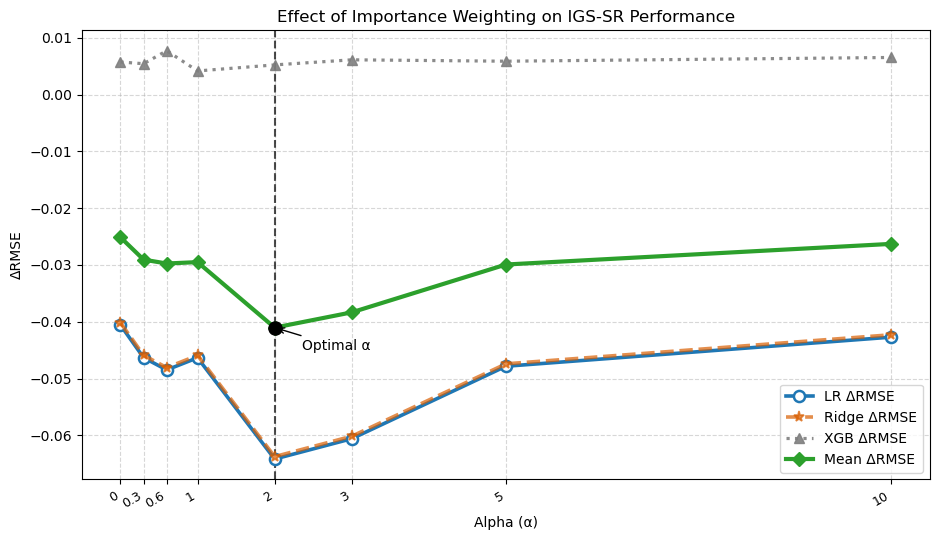

In [26]:
# Cell 14c: Ablation plot (alpha vs ΔRMSE) with clearer styling

import matplotlib.pyplot as plt
import numpy as np

# ---- Data (from your results) ----
alphas = [0.0, 0.3, 0.6, 1.0, 2.0, 3.0, 5.0, 10.0]

lr_drmse = [
    -0.040569, -0.046308, -0.048473, -0.046330,
    -0.064162, -0.060581, -0.047824, -0.042697,
]

ridge_drmse = [
    -0.040548, -0.046290, -0.048459, -0.046310,
    -0.064133, -0.060547, -0.047801, -0.042680,
]

xgb_drmse = [
    0.005738, 0.005427, 0.007713, 0.004157,
    0.005220, 0.006117, 0.005871, 0.006530,
]

mean_drmse = [
    -0.025127, -0.029057, -0.029740, -0.029494,
    -0.041025, -0.038337, -0.029918, -0.026283,
]

# Tiny visual offset so LR and Ridge can be distinguished when they overlap
epsilon = 0.0004
ridge_drmse_vis = [v + epsilon for v in ridge_drmse]

# ---- Plot ----
fig, ax = plt.subplots(figsize=(9.5, 5.5))

# LR: solid blue, hollow circles
ax.plot(
    alphas, lr_drmse,
    color='#1f77b4',
    marker='o',
    linestyle='-',
    linewidth=2.6,
    markersize=8,
    markerfacecolor='white',
    markeredgewidth=1.8,
    label='LR ΔRMSE',
    zorder=4
)

# Ridge: triangle markers, dashed line, slightly transparent
ax.plot(
    alphas, ridge_drmse_vis,
    color='#d95f02',
    marker='*',
    linestyle='--',
    linewidth=2.6,
    markersize=8,
    markerfacecolor='#d95f02',
    markeredgewidth=1.2,
    alpha=0.7,
    label='Ridge ΔRMSE',
    zorder=5
)

# XGB
ax.plot(
    alphas, xgb_drmse,
    color='#7f7f7f',
    marker='^',
    linestyle=':',
    linewidth=2.3,
    markersize=7,
    alpha=0.9,
    label='XGB ΔRMSE',
    zorder=3
)

# Mean: thick green line with diamonds
ax.plot(
    alphas, mean_drmse,
    color='#2ca02c',
    marker='D',
    linestyle='-',
    linewidth=3.0,
    markersize=7,
    markerfacecolor='#2ca02c',
    label='Mean ΔRMSE',
    zorder=2
)

# Highlight α = 2.0
alpha_opt = 2.0
idx_opt = alphas.index(alpha_opt)

ax.scatter(
    alpha_opt,
    mean_drmse[idx_opt],
    color='black',
    s=90,
    zorder=6
)

# Vertical dashed line
ax.axvline(x=alpha_opt, linestyle='--', color='black', alpha=0.7, zorder=1)

# Annotation
ax.annotate(
    'Optimal α',
    xy=(alpha_opt, mean_drmse[idx_opt]),
    xytext=(2.35, -0.045),
    fontsize=10,
    arrowprops=dict(arrowstyle='->', lw=1.0, color='black')
)

# X-axis labels: prevent overlap
ax.set_xticks(alphas)
ax.set_xticklabels([f'{a:g}' for a in alphas], rotation=30, ha='right')
ax.tick_params(axis='x', labelsize=9)

# Labels
ax.set_xlabel('Alpha (α)')
ax.set_ylabel('ΔRMSE')
ax.set_title('Effect of Importance Weighting on IGS-SR Performance')

# Grid & legend
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.legend()

# Give a little horizontal breathing room
ax.margins(x=0.05)

plt.tight_layout()
plt.savefig('/home/rshayan1/artifacts/artifacts/Plots/alpha_ablation_plot.png',
            dpi=300, bbox_inches='tight')
plt.show()

## Robustness Plot (Training Fraction) — STABILITY

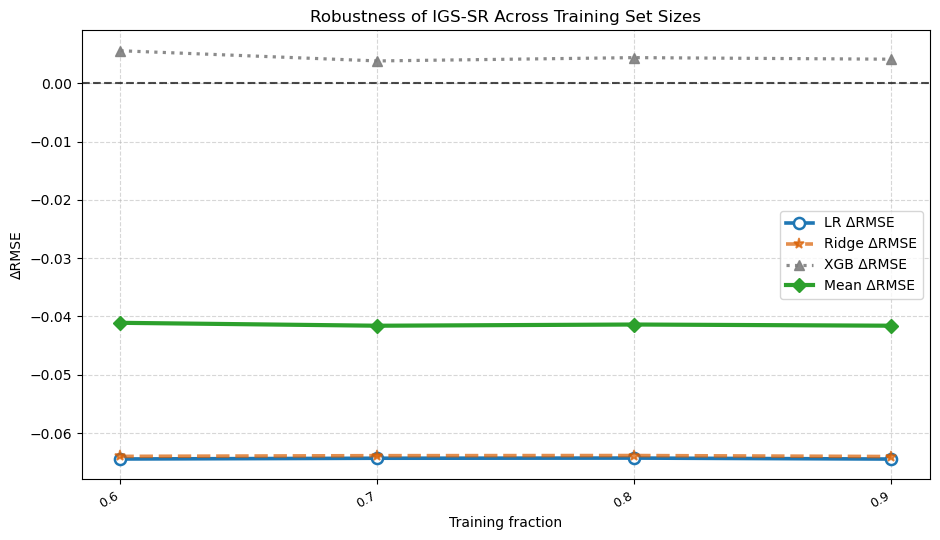

In [27]:
# Cell 12c: Robustness plot (training fraction - styled same as ablation)

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

agg_path = Path("/home/rshayan1/artifacts/artifacts/robustness_test1_subsampling_alpha_2.0_20260321_181210/robustness_test1_agg.csv")
df = pd.read_csv(agg_path, header=[0, 1], index_col=0)

# Flatten columns
df.columns = [f"{a}_{b}" for a, b in df.columns]
df = df.sort_index()

x = df.index.astype(float).values

lr_mean = df["LR_dRMSE_mean"].values
ridge_mean = df["Ridge_dRMSE_mean"].values
xgb_mean = df["XGB_dRMSE_mean"].values
mean_mean = df["mean_dRMSE_mean"].values

# Small offset (same idea as ablation)
epsilon = 0.0004
ridge_mean_vis = [v + epsilon for v in ridge_mean]

# ---- Plot ----
fig, ax = plt.subplots(figsize=(9.5, 5.5))

# LR: solid blue, hollow circles
ax.plot(
    x, lr_mean,
    color='#1f77b4',
    marker='o',
    linestyle='-',
    linewidth=2.6,
    markersize=8,
    markerfacecolor='white',
    markeredgewidth=1.8,
    label='LR ΔRMSE',
    zorder=4
)

# Ridge: triangle markers, dashed line, slightly transparent
ax.plot(
    x, ridge_mean_vis,
    color='#d95f02',
    marker='*',
    linestyle='--',
    linewidth=2.6,
    markersize=8,
    markerfacecolor='#d95f02',
    markeredgewidth=1.2,
    alpha=0.70,
    label='Ridge ΔRMSE',
    zorder=5
)

# XGB
ax.plot(
    x, xgb_mean,
    color='#7f7f7f',
    marker='^',
    linestyle=':',
    linewidth=2.3,
    markersize=7,
    alpha=0.9,
    label='XGB ΔRMSE',
    zorder=3
)

# Mean: thick green line with diamonds
ax.plot(
    x, mean_mean,
    color='#2ca02c',
    marker='D',
    linestyle='-',
    linewidth=3.0,
    markersize=7,
    markerfacecolor='#2ca02c',
    label='Mean ΔRMSE',
    zorder=2
)

# Zero reference line (same style)
ax.axhline(0, linestyle='--', color='black', alpha=0.7, zorder=1)

# X-axis ticks
ax.set_xticks(x)
ax.set_xticklabels([f'{v:.1f}' for v in x], rotation=30, ha='right')
ax.tick_params(axis='x', labelsize=9)

# Labels
ax.set_xlabel('Training fraction')
ax.set_ylabel('ΔRMSE')
ax.set_title('Robustness of IGS-SR Across Training Set Sizes')

# Grid & legend (same style)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.legend()

# Breathing room
ax.margins(x=0.05)

plt.tight_layout()
plt.savefig('/home/rshayan1/artifacts/artifacts/Plots/robustness_train_fraction_plot.png',
            dpi=300, bbox_inches='tight')

plt.show()

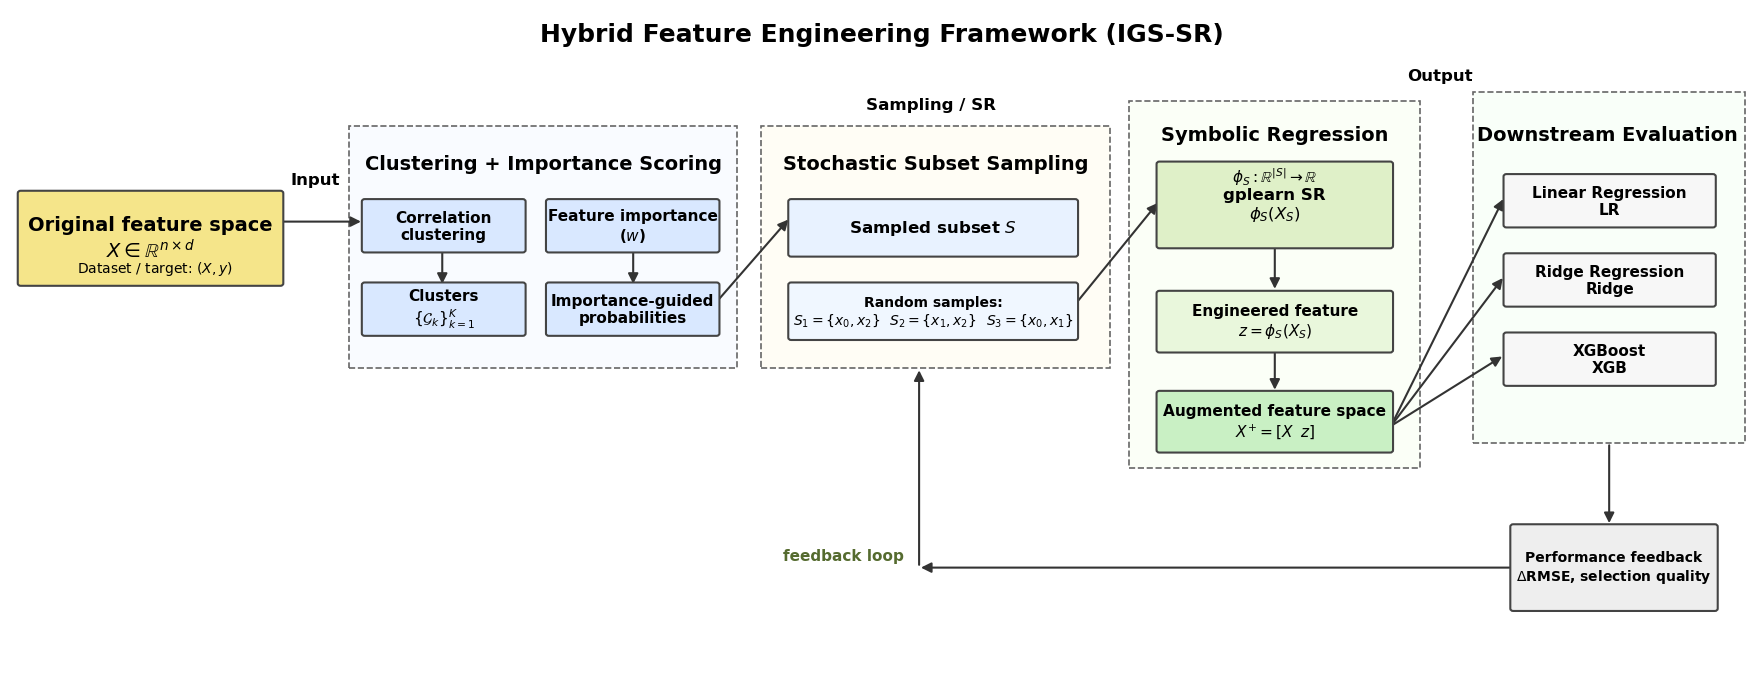

In [270]:
# Framework figure for the proposed hybrid pipeline

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
from matplotlib import rcParams

rcParams["font.size"] = 11
rcParams["mathtext.fontset"] = "dejavusans"

def add_box(ax, xy, w, h, text, fc="#f6f6f6", ec="#444444",
            text_size=11, weight="normal", rounded=True, lw=1.5, zorder=2):
    x, y = xy
    boxstyle = "round,pad=0.02,rounding_size=0.03" if rounded else "square,pad=0.02"
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle=boxstyle,
        linewidth=lw,
        edgecolor=ec,
        facecolor=fc,
        zorder=zorder
    )
    ax.add_patch(patch)
    ax.text(
        x + w / 2, y + h / 2, text,
        ha="center", va="center",
        fontsize=text_size, fontweight=weight,
        zorder=zorder + 1
    )
    return patch

def add_arrow(ax, p1, p2, color="#333333", lw=1.5, style="-|>", mutation_scale=15,
              connectionstyle="arc3,rad=0.0", zorder=1):
    arr = FancyArrowPatch(
        p1, p2,
        arrowstyle=style,
        mutation_scale=mutation_scale,
        linewidth=lw,
        color=color,
        connectionstyle=connectionstyle,
        zorder=zorder
    )
    ax.add_patch(arr)
    return arr

fig, ax = plt.subplots(figsize=(18, 7))
ax.set_xlim(0, 18)
ax.set_ylim(0, 8)
ax.axis("off")

# Colors
c_input = "#f5e58a"
c_cluster = "#d9e8ff"
c_sample = "#e8f2ff"
c_sr = "#dff0c8"
c_aug = "#c9f0c4"
c_feedback = "#f2f2f2"
c_model = "#f7f7f7"
c_perf = "#eeeeee"

# Left: original data / feature space
add_box(
    ax, (0.1, 4.7), 2.7, 1.1,
    r"Original feature space" "\n" r"$X \in \mathbb{R}^{n \times d}$",
    fc=c_input, text_size=14, weight="bold"
)
ax.text(1.50, 4.89, r"Dataset / target: $(X, y)$", ha="center", va="center", fontsize=10)

# Clustering / importance scoring block
ax.add_patch(Rectangle((3.5, 3.7), 4.0, 2.9, linewidth=1.2, edgecolor="#666666",
                       facecolor="#f9fbff", linestyle="--", zorder=0))
ax.text(5.5, 6.15, "Clustering + Importance Scoring", ha="center", va="center", fontsize=14, fontweight="bold")

add_box(ax, (3.65, 5.1), 1.65, 0.6, "Correlation\nclustering", fc=c_cluster, text_size=11, weight="bold")
add_box(ax, (5.55, 5.1), 1.75, 0.6, r"Feature importance" "\n" r"($w$)", fc=c_cluster, text_size=11, weight="bold")
add_box(ax, (3.65, 4.1), 1.65, 0.6, r"Clusters" "\n" r"$\{\mathcal{G}_k\}_{k=1}^{K}$", fc=c_cluster, text_size=11, weight="bold")
add_box(ax, (5.55, 4.1), 1.75, 0.6, r"Importance-guided" "\n" r"probabilities", fc=c_cluster, text_size=11, weight="bold")

add_arrow(ax, (2.7, 5.45), (3.65, 5.45))
add_arrow(ax, (4.46, 5.7), (4.46, 4.67), connectionstyle="arc3,rad=0.0")
add_arrow(ax, (6.43, 5.7), (6.43, 4.67), connectionstyle="arc3,rad=0.0")

# Stochastic sampling block
ax.add_patch(Rectangle((7.75, 3.7), 3.6, 2.9, linewidth=1.2, edgecolor="#666666",
                       facecolor="#fffdf5", linestyle="--", zorder=0))
ax.text(9.55, 6.15, "Stochastic Subset Sampling", ha="center", va="center", fontsize=14, fontweight="bold")

add_box(ax, (8.05, 5.05), 2.95, 0.65, r"Sampled subset $S$", fc=c_sample, text_size=12, weight="bold")
add_box(
    ax, (8.05, 4.05), 2.95, 0.65,
    r"Random samples:" "\n" r"$S_1=\{x_0,x_2\}$  $S_2=\{x_1,x_2\}$  $S_3=\{x_0,x_1\}$",
    fc="#f0f7ff", text_size=10, weight="bold"
)

add_arrow(ax, (7.3, 4.5), (8.05, 5.5))

# SR block
ax.add_patch(Rectangle((11.55, 2.5), 3.0, 4.4, linewidth=1.2, edgecolor="#666666",
                       facecolor="#fbfff7", linestyle="--", zorder=0))
ax.text(13.05, 6.50, "Symbolic Regression", ha="center", va="center", fontsize=14, fontweight="bold")

# This is the consistent mapping with the methodology section
ax.text(
    13.05, 6.0,
    r"$\phi_S : \mathbb{R}^{|S|} \rightarrow \mathbb{R}$",
    ha="center", va="center", fontsize=11
)

add_box(ax, (11.85, 5.15), 2.4, 1.0, r"gplearn SR" "\n" r"$\phi_S(X_S)$", fc=c_sr, text_size=12, weight="bold")
add_box(ax, (11.85, 3.9), 2.4, 0.7, r"Engineered feature" "\n" r"$z = \phi_S(X_S)$", fc="#e9f7dc", text_size=11, weight="bold")
add_box(ax, (11.85, 2.7), 2.4, 0.7, r"Augmented feature space" "\n" r"$X^{+} = [X \;\; z]$", fc=c_aug, text_size=11, weight="bold")

add_arrow(ax, (10.95, 4.4), (11.86, 5.7))
add_arrow(ax, (13.05, 5.35), (13.05, 4.61))
add_arrow(ax, (13.05, 4.25), (13.05, 3.4))

# Downstream models block
ax.add_patch(Rectangle((15.1, 2.8), 2.80, 4.2, linewidth=1.2, edgecolor="#666666",
                       facecolor="#f9fff9", linestyle="--", zorder=0))
ax.text(16.48, 6.50, "Downstream Evaluation", ha="center", va="center", fontsize=14, fontweight="bold")

add_box(ax, (15.43, 5.40), 2.15, 0.6, "Linear Regression\nLR", fc=c_model, text_size=11, weight="bold")
add_box(ax, (15.43, 4.45), 2.15, 0.6, "Ridge Regression\nRidge", fc=c_model, text_size=11, weight="bold")
add_box(ax, (15.43, 3.50), 2.15, 0.6, "XGBoost\nXGB", fc=c_model, text_size=11, weight="bold")

add_arrow(ax, (14.25, 3.0), (15.42, 5.75))
add_arrow(ax, (14.25, 3.0), (15.42, 4.8))
add_arrow(ax, (14.25, 3.0), (15.42, 3.85))

# Performance feedback block
add_box(ax, (15.5, 0.8), 2.1, 1.0, r"Performance feedback" "\n" r"$\Delta$RMSE, selection quality", fc=c_perf, text_size=10, weight="bold")
add_arrow(ax, (16.5, 2.8), (16.5, 1.8))
add_arrow(ax, (15.6, 1.3), (9.37, 1.3), connectionstyle="arc3,rad=0.0")
add_arrow(ax, (9.38, 1.3), (9.38, 3.7))
ax.text(8.6, 1.45, "feedback loop", ha="center", va="center", fontsize=11, fontweight="bold", color="#556b2f")

# Additional labels
ax.text(3.15, 5.95, "Input", ha="center", va="center", fontsize=12, fontweight="bold")
ax.text(9.5, 6.85, "Sampling / SR", ha="center", va="center", fontsize=12, fontweight="bold")
ax.text(14.75, 7.2, "Output", ha="center", va="center", fontsize=12, fontweight="bold")

# Title
ax.text(9.0, 7.7, "Hybrid Feature Engineering Framework (IGS-SR)", ha="center", va="center",
        fontsize=18, fontweight="bold")

plt.tight_layout()
plt.savefig("/home/rshayan1/artifacts/artifacts/Plots/hybrid_framework_figure.png", dpi=300, bbox_inches="tight")
plt.savefig("/home/rshayan1/artifacts/artifacts/Plots/hybrid_framework_figure.pdf", dpi=300, bbox_inches="tight")
plt.show()